# Used Car Resale Price Analysis — Exploratory Data Analysis
### Understanding what drives sold prices before building a seller-facing price estimator

**Dataset:** Historical used-car sales (200 vehicles, 26 attributes: specifications, insurance risk ratings, and the price each car sold for)
**Scope:** Business framing → data quality audit → cleaning → univariate / bivariate / multivariate analysis → statistical testing → feature ideas → findings → machine learning readiness plan


## 01. Business Context

### Business Problem
Anyone selling a used car faces the same question: *what is it worth?* Ask too much and the car sits unsold; ask too little and money is left on the table. Most sellers have no reliable reference, and guessing from a few online listings is noisy.

This project uses a **historical dataset of used cars and the prices they actually sold for**. The idea is that a seller can describe their car (make, body style, engine, size, and so on) and receive the **expected sale price, based on what similar cars with similar features sold for in the past**. This notebook is the EDA stage: it establishes what the historical data can and cannot support before any prediction model is built.

### Analytical Objectives
1. Audit the historical sales data for quality problems before any modelling (missing values, typos, impossible values, outliers).
2. Understand the shape of the target (`price`, the historical sold price) and decide whether it needs transformation.
3. Identify which vehicle features are most strongly associated with sold price.
4. Separate the effect of *brand* from the effect of *specifications*, since sellers care about both.
5. Detect redundant features, so the future seller input form stays short and the model stays stable.
6. Judge which features a seller could realistically supply, and which they could not.
7. Test whether price differences across categories are statistically real, not just visual.
8. Produce a concrete machine learning readiness plan grounded in what the EDA found.

### Key Business Questions
- What does the sold-price distribution look like, and is a plain-scale target safe to model?
- Which features move a used car's sold price the most (size, power, weight, efficiency, brand, drivetrain)?
- How much of the sold price is explained by brand versus engineering specifications?
- Are some features so correlated that a seller would be asked for the same information twice?
- Is there enough data for every kind of car a seller might describe, or are some types too rare to estimate reliably?
- Is the missing data random, or does it hide a pattern?


## Environment Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 12

ACCENT = '#2E86AB'
HIGHLIGHT = '#E63946'
SEED = 42


## 02. Dataset Overview

In [3]:
raw = pd.read_csv(r"C:\Users\USER\Desktop\COURSERA PROJECT DATA\automobile.csv")
df = raw.copy()
df.columns = [c.strip().replace('-', '_') for c in df.columns]   # python-friendly names
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(8)

Dimensions: 200 rows x 26 columns


,symboling,normalized_losses,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,height,curb_weight,engine_type,num_of_cylinders,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,3,NaN,alfa-romero,gas,std,two,convertible,rwd,front,88.60,168.80,64.10,48.80,2548,dohc,four,130,mpfi,3.47,2.68,9.00,111.00,"5,000.00",21,27,16500
1,1,NaN,alfa-romero,gas,std,two,hatchback,rwd,front,94.50,171.20,65.50,52.40,2823,ohcv,six,152,mpfi,2.68,3.47,9.00,154.00,"5,000.00",19,26,16500
2,2,164.00,audi,gas,std,four,sedan,fwd,front,99.80,176.60,66.20,54.30,2337,ohc,four,109,mpfi,3.19,3.40,10.00,102.00,"5,500.00",24,30,13950
3,2,164.00,audi,gas,std,four,sedan,4wd,front,99.40,176.60,66.40,54.30,2824,ohc,five,136,mpfi,3.19,3.40,8.00,115.00,"5,500.00",18,22,17450
4,2,NaN,audi,gas,std,two,sedan,fwd,front,99.80,177.30,66.30,53.10,2507,ohc,five,136,mpfi,3.19,3.40,8.50,110.00,"5,500.00",19,25,15250
5,1,158.00,audi,gas,std,four,sedan,fwd,front,105.80,192.70,71.40,55.70,2844,ohc,five,136,mpfi,3.19,3.40,8.50,110.00,"5,500.00",19,25,17710
6,1,NaN,audi,gas,std,four,wagon,fwd,front,105.80,192.70,71.40,55.70,2954,ohc,five,136,mpfi,3.19,3.40,8.50,110.00,"5,500.00",19,25,18920
7,1,158.00,audi,gas,turbo,four,sedan,fwd,front,105.80,192.70,71.40,55.90,3086,ohc,five,131,mpfi,3.13,3.40,8.30,140.00,"5,500.00",17,20,23875


In [4]:
# Schema, data types, completeness and cardinality in one table
schema = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'non_null': df.notnull().sum(),
    'missing': df.isnull().sum(),
    'missing_%': (df.isnull().mean() * 100).round(1),
    'n_unique': df.nunique(),
})
numeric_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = [c for c in df.columns if c not in numeric_cols]
print(f"{len(numeric_cols)} numeric columns | {len(cat_cols)} categorical columns")
schema

16 numeric columns | 10 categorical columns


,dtype,non_null,missing,missing_%,n_unique
symboling,int64,200,0,0.00,6
normalized_losses,float64,164,36,18.00,51
make,object,200,0,0.00,22
fuel_type,object,200,0,0.00,2
aspiration,object,200,0,0.00,2
num_of_doors,object,198,2,1.00,2
body_style,object,200,0,0.00,5
drive_wheels,object,200,0,0.00,3
engine_location,object,200,0,0.00,2
wheel_base,float64,200,0,0.00,52


In [5]:
df[numeric_cols].describe().T.assign(skew=df[numeric_cols].skew(), kurtosis=df[numeric_cols].kurt())

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
symboling,200.00,0.83,1.25,-2.00,0.00,1.00,2.00,3.00,0.20,-0.69
normalized_losses,164.00,122.00,35.44,65.00,94.00,115.00,150.00,256.00,0.77,0.53
wheel_base,200.00,98.85,6.04,86.60,94.50,97.00,102.40,120.90,1.05,0.97
length,200.00,174.23,12.35,141.10,166.68,173.20,183.50,208.10,0.15,-0.08
width,200.00,65.90,2.10,60.30,64.17,65.50,66.67,72.00,0.87,0.67
height,200.00,53.79,2.43,47.80,52.00,54.10,55.52,59.80,0.04,-0.43
curb_weight,200.00,"2,555.70",518.59,"1,488.00","2,163.00","2,414.00","2,928.25","4,066.00",0.70,0.02
engine_size,200.00,126.86,41.65,61.00,97.75,119.50,142.00,326.00,1.98,5.46
bore,196.00,3.33,0.27,2.54,3.15,3.31,3.59,3.94,-0.03,-0.85
stroke,196.00,3.26,0.32,2.07,3.11,3.29,3.41,4.17,-0.71,2.15


In [6]:
df[cat_cols].describe().T

,count,unique,top,freq
make,200,22,toyota,32
fuel_type,200,2,gas,180
aspiration,200,2,std,164
num_of_doors,198,2,four,113
body_style,200,5,sedan,94
drive_wheels,200,3,fwd,118
engine_location,200,2,front,197
engine_type,200,6,ohc,145
num_of_cylinders,200,7,four,156
fuel_system,200,8,mpfi,91


**Insights — Dataset overview**
- 200 cars × 26 columns: numeric specifications, ten categorical descriptors (make, body style, drive wheels and so on) and the target `price`.
- `price` is complete. Missing values are confined to six columns: `normalized_losses` (18%) and five others with 2% or less.


## 03. Data Quality & Validation

,missing,missing_%
normalized_losses,36,18.00
bore,4,2.00
stroke,4,2.00
num_of_doors,2,1.00
horsepower,2,1.00
peak_rpm,2,1.00


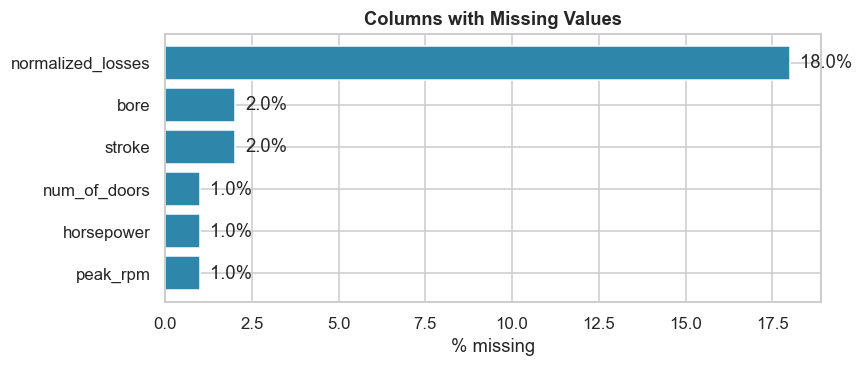

In [7]:
# --- Missing values: how much, and where? ---
miss = df.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_df = pd.DataFrame({'missing': miss, 'missing_%': (miss / len(df) * 100).round(1)})
display(miss_df)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(miss_df.index[::-1], miss_df['missing_%'][::-1], color=ACCENT)
for i, v in enumerate(miss_df['missing_%'][::-1]):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center')
ax.set_xlabel('% missing'); ax.set_title('Columns with Missing Values')
plt.tight_layout(); plt.show()

In [8]:
# --- Is the missingness random? ---
# normalized_losses is by far the largest gap. If it is missing for a particular kind of car,
# then simple imputation hides a pattern. Compare price and make mix of missing vs present rows.
nl_missing = df['normalized_losses'].isnull()
print(f"Median price WHERE normalized_losses is missing : {df.loc[nl_missing, 'price'].median():>10,.0f}")
print(f"Median price WHERE normalized_losses is present : {df.loc[~nl_missing, 'price'].median():>10,.0f}")
u, p = stats.mannwhitneyu(df.loc[nl_missing, 'price'], df.loc[~nl_missing, 'price'])
print(f"Mann-Whitney U test p-value: {p:.2e}  ->  {'NOT random' if p < 0.05 else 'consistent with random'}")

share_missing_by_make = df.groupby('make')['normalized_losses'].apply(lambda s: s.isnull().mean() * 100).sort_values(ascending=False)
print("\nMakes where normalized_losses is missing for most/all rows (% missing):")
print(share_missing_by_make[share_missing_by_make > 0].round(0).to_string())

Median price WHERE normalized_losses is missing :     16,500
Median price WHERE normalized_losses is present :      9,268
Mann-Whitney U test p-value: 1.52e-08  ->  NOT random

Makes where normalized_losses is missing for most/all rows (% missing):
make
alfa-romero     100.00
renault         100.00
isuzu           100.00
mercury         100.00
porsche          75.00
jaguar           67.00
bmw              50.00
mercedes-benz    38.00
peugot           36.00
audi             33.00
volkswagen       33.00
mitsubishi       23.00
plymouth         14.00
mazda            12.00
toyota            3.00


In [9]:
# --- Duplicates ---
print(f"Fully duplicated rows: {df.duplicated().sum()}")

# --- Categorical consistency: look for typos / inconsistent labels ---
for c in cat_cols:
    vals = sorted(df[c].dropna().unique())
    print(f"{c:<18} ({len(vals)}): {vals}")

Fully duplicated rows: 0
make               (22): ['alfa-romero', 'audi', 'bmw', 'chevrolet', 'dodge', 'honda', 'isuzu', 'jaguar', 'mazda', 'mercedes-benz', 'mercury', 'mitsubishi', 'nissan', 'peugot', 'plymouth', 'porsche', 'renault', 'saab', 'subaru', 'toyota', 'volkswagen', 'volvo']
fuel_type          (2): ['diesel', 'gas']
aspiration         (2): ['std', 'turbo']
num_of_doors       (2): ['four', 'two']
body_style         (5): ['convertible', 'hardtop', 'hatchback', 'sedan', 'wagon']
drive_wheels       (3): ['4wd', 'fwd', 'rwd']
engine_location    (2): ['front', 'rear']
engine_type        (6): ['dohc', 'l', 'ohc', 'ohcf', 'ohcv', 'rotor']
num_of_cylinders   (7): ['eight', 'five', 'four', 'six', 'three', 'twelve', 'two']
fuel_system        (8): ['1bbl', '2bbl', '4bbl', 'idi', 'mfi', 'mpfi', 'spdi', 'spfi']


In [10]:
# --- Typo fix: 'peugot' is a misspelling of Peugeot ---
df['make'] = df['make'].replace({'peugot': 'peugeot'})
print('make values after correction:', df['make'].nunique())

make values after correction: 22


In [11]:
# --- Range & logical validation ---
checks = {
    'price <= 0'                                : (df.price <= 0).sum(),
    'symboling outside [-3, 3]'                 : (~df.symboling.between(-3, 3)).sum(),
    'width >= length (impossible geometry)'     : (df.width >= df.length).sum(),
    'wheel_base >= length (impossible geometry)': (df.wheel_base >= df.length).sum(),
    'highway_mpg < city_mpg (implausible)'      : (df.highway_mpg < df.city_mpg).sum(),
    'horsepower <= 0'                           : (df.horsepower <= 0).sum(),
    'engine_size <= 0'                          : (df.engine_size <= 0).sum(),
    'curb_weight <= 0'                          : (df.curb_weight <= 0).sum(),
    'compression_ratio < 6'                     : (df.compression_ratio < 6).sum(),
}
pd.Series(checks, name='violations').to_frame()

,violations
price <= 0,0
"symboling outside [-3, 3]",0
width >= length (impossible geometry),0
wheel_base >= length (impossible geometry),0
highway_mpg < city_mpg (implausible),0
horsepower <= 0,0
engine_size <= 0,0
curb_weight <= 0,0
compression_ratio < 6,0


In [12]:
# --- Compression ratio: bimodal because diesel engines run far higher compression than petrol engines.
# That is a real engineering fact, not an error - confirm before treating the high values as outliers.
print(df.groupby('fuel_type')['compression_ratio'].describe()[['count', 'min', 'mean', 'max']])

           count   min  mean   max
fuel_type                         
diesel     20.00 21.00 22.01 23.00
gas       180.00  7.00  8.86 11.50


### Missing Value Treatment
Decisions, with reasoning (applied to a copy so the raw data stays untouched):

| Column | Strategy | Why |
|---|---|---|
| `normalized_losses` | Median by `symboling` group + a `normalized_losses_missing` flag | It is an insurance risk metric tightly tied to `symboling`; the flag preserves the fact that missingness itself is informative (it is not random, see test above) |
| `num_of_doors` | Mode within `body_style` | Door count is largely determined by body style |
| `bore`, `stroke`, `horsepower`, `peak_rpm` | Median by `make` (global median as fallback) | Only 2–4 rows each; same manufacturer builds similar engines |


In [13]:
clean = df.copy()

# normalized_losses
clean['normalized_losses_missing'] = clean['normalized_losses'].isnull().astype(int)
clean['normalized_losses'] = clean['normalized_losses'].fillna(
    clean.groupby('symboling')['normalized_losses'].transform('median'))
clean['normalized_losses'] = clean['normalized_losses'].fillna(clean['normalized_losses'].median())

# num_of_doors: mode within body_style
mode_by_body = clean.groupby('body_style')['num_of_doors'].agg(lambda s: s.mode().iat[0])
clean['num_of_doors'] = clean['num_of_doors'].fillna(clean['body_style'].map(mode_by_body))

# small numeric gaps: median by make, global median fallback
for col in ['bore', 'stroke', 'horsepower', 'peak_rpm']:
    clean[col] = clean[col].fillna(clean.groupby('make')[col].transform('median'))
    clean[col] = clean[col].fillna(clean[col].median())

print('Remaining missing values:', int(clean.drop(columns=[]).isnull().sum().sum()))

Remaining missing values: 0


In [14]:
print("DATA QUALITY SUMMARY")
print("=" * 60)
print(f"Rows                        : {len(df):,}")
print(f"Duplicate rows              : {df.duplicated().sum()}")
print(f"Columns with missing values : {int((df.isnull().sum() > 0).sum())} (all treated)")
print(f"Label typos corrected       : 1 ('peugot' -> 'peugeot')")
print(f"Logical / range violations  : {sum(checks.values())}")
print("Verdict: small, clean dataset. Main caveat is non-random missingness in normalized_losses.")
print("Small sample (n=200) will matter later: it limits model complexity and favours cross-validation.")

DATA QUALITY SUMMARY
Rows                        : 200
Duplicate rows              : 0
Columns with missing values : 6 (all treated)
Label typos corrected       : 1 ('peugot' -> 'peugeot')
Logical / range violations  : 0
Verdict: small, clean dataset. Main caveat is non-random missingness in normalized_losses.
Small sample (n=200) will matter later: it limits model complexity and favours cross-validation.


**Insights — Data quality**
- The data is clean: no duplicates, no impossible values, and one label typo (`peugot`) corrected.
- The one issue that matters is non-random missingness in `normalized_losses`: it is missing mostly for luxury makes, so cars with the gap have a median price about 1.8 times higher (16,500 vs 9,268). The missing-value flag keeps that signal.
- Compression ratio is bimodal because diesel engines legitimately run higher compression; it is not a data error.


## 04. Target Variable Analysis — `price` (historical sold price)

count                 200.00
mean               13,205.69
median             10,270.00
std                 7,966.98
min                 5,118.00
max                45,400.00
skew                    1.81
kurtosis                3.20
skew (log price)        0.68


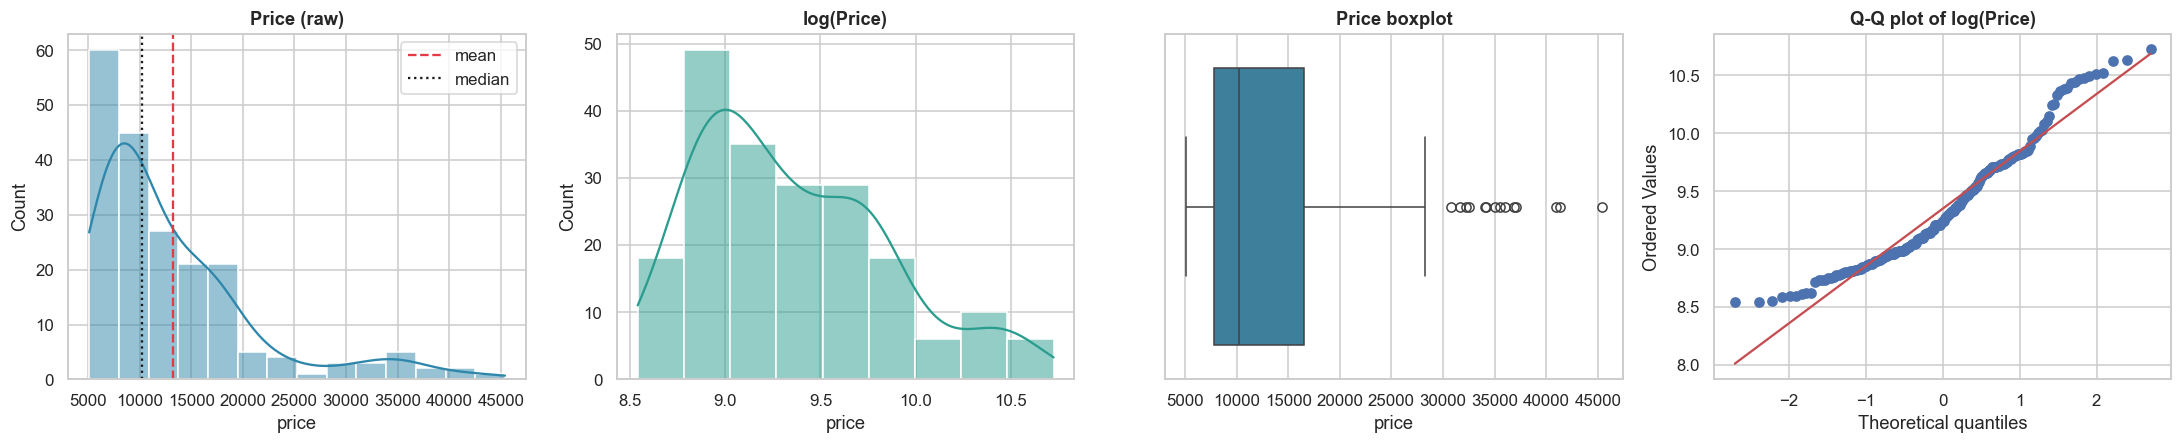

In [15]:
price = clean['price']
summary = pd.Series({
    'count': price.count(), 'mean': price.mean(), 'median': price.median(), 'std': price.std(),
    'min': price.min(), 'max': price.max(), 'skew': price.skew(), 'kurtosis': price.kurt(),
    'skew (log price)': np.log(price).skew(),
})
print(summary.round(2).to_string())

fig, axes = plt.subplots(1, 4, figsize=(20, 4.2))
sns.histplot(price, kde=True, ax=axes[0], color=ACCENT); axes[0].set_title('Price (raw)')
axes[0].axvline(price.mean(), color=HIGHLIGHT, ls='--', label='mean'); axes[0].axvline(price.median(), color='k', ls=':', label='median'); axes[0].legend()
sns.histplot(np.log(price), kde=True, ax=axes[1], color='#2A9D8F'); axes[1].set_title('log(Price)')
sns.boxplot(x=price, ax=axes[2], color=ACCENT); axes[2].set_title('Price boxplot')
stats.probplot(np.log(price), dist='norm', plot=axes[3]); axes[3].set_title('Q-Q plot of log(Price)')
plt.tight_layout(); plt.show()

In [16]:
# Price segments - a seller-friendly lens (what kind of car is being sold) used throughout the notebook
bins = [0, 8000, 16000, 30000, np.inf]
labels = ['Budget (<8K)', 'Mid (8-16K)', 'Upper (16-30K)', 'Luxury (30K+)']
clean['price_segment'] = pd.cut(clean['price'], bins=bins, labels=labels)
seg = clean.groupby('price_segment', observed=True).agg(
    cars=('price', 'size'), median_price=('price', 'median'), avg_hp=('horsepower', 'mean'),
    avg_engine=('engine_size', 'mean'), avg_weight=('curb_weight', 'mean'))
seg['share_%'] = (seg['cars'] / seg['cars'].sum() * 100).round(1)
seg

,cars,median_price,avg_hp,avg_engine,avg_weight,share_%
price_segment,,,,,,
Budget (<8K),61,"6,938.00",70.31,95.92,"2,034.64",30.50
Mid (8-16K),86,"10,746.50",102.30,121.98,"2,564.21",43.00
Upper (16-30K),39,"18,280.00",127.85,146.59,"3,004.79",19.50
Luxury (30K+),14,"35,303.00",184.43,236.71,"3,522.79",7.00


**Reading the target:** the sold price is strongly right-skewed (mean well above median, long upper tail). The log transform cuts skewness from about 1.81 to 0.68 and makes the Q-Q plot much straighter (still a mild right tail, but far more regular). That is a direct modelling decision for later: most regression algorithms behave better on `log(price)`, and because a seller cares about being 10% off (not about a fixed 800 on a cheap car versus a luxury car), errors should be judged in relative (%) terms, not just in currency units.

## 05. Univariate Analysis — Numeric Features

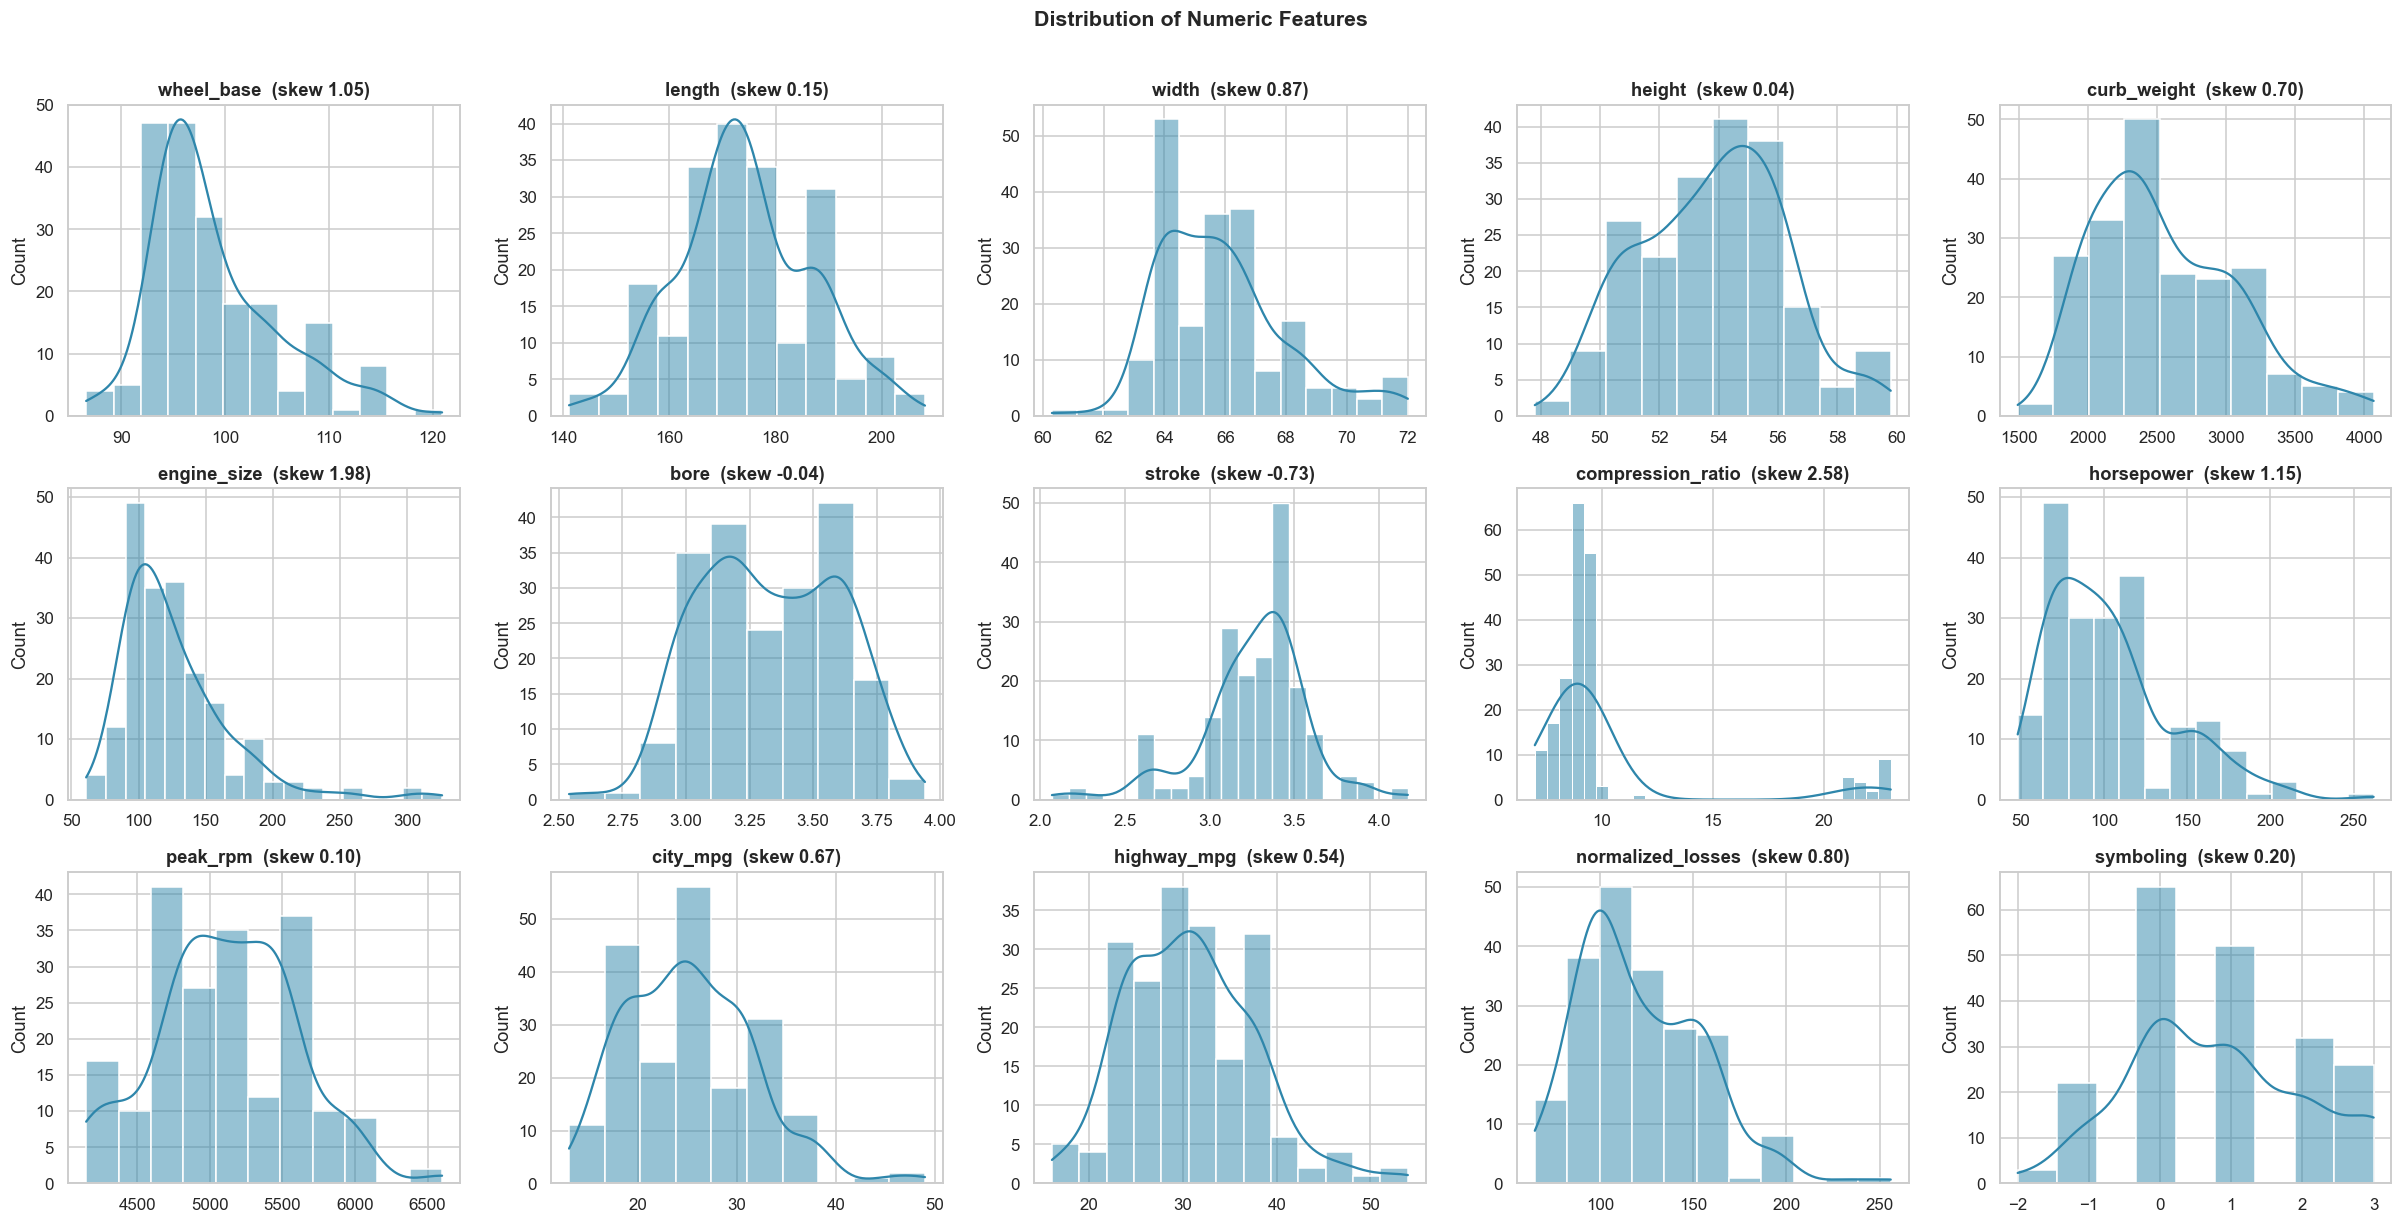

In [17]:
num_features = ['wheel_base', 'length', 'width', 'height', 'curb_weight', 'engine_size', 'bore',
                'stroke', 'compression_ratio', 'horsepower', 'peak_rpm', 'city_mpg', 'highway_mpg',
                'normalized_losses', 'symboling']

fig, axes = plt.subplots(3, 5, figsize=(22, 11))
for ax, col in zip(axes.flatten(), num_features):
    sns.histplot(clean[col], kde=True, ax=ax, color=ACCENT)
    ax.set_title(f"{col}  (skew {clean[col].skew():.2f})")
    ax.set_xlabel('')
plt.suptitle('Distribution of Numeric Features', y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

In [18]:
skew_table = clean[num_features].skew().sort_values(ascending=False).to_frame('skew')
skew_table['verdict'] = np.where(skew_table['skew'].abs() > 1, 'highly skewed',
                          np.where(skew_table['skew'].abs() > 0.5, 'moderately skewed', 'roughly symmetric'))
skew_table

,skew,verdict
compression_ratio,2.58,highly skewed
engine_size,1.98,highly skewed
horsepower,1.15,highly skewed
wheel_base,1.05,highly skewed
width,0.87,moderately skewed
normalized_losses,0.80,moderately skewed
curb_weight,0.70,moderately skewed
city_mpg,0.67,moderately skewed
highway_mpg,0.54,moderately skewed
symboling,0.20,roughly symmetric


**Insights — Numeric distributions**
- Length, height, bore, peak RPM and symboling are close to symmetric (|skew| ≤ 0.2).
- Right-skew appears in the size-and-power variables, mirroring price: `compression_ratio` (2.58, driven by diesel engines), `engine_size` (1.98), `horsepower` (1.14) and `wheel_base` (1.05).
- Implication: linear and distance-based models benefit from scaling or transformation of these variables; tree models are insensitive.


## 06. Univariate Analysis — Categorical Features

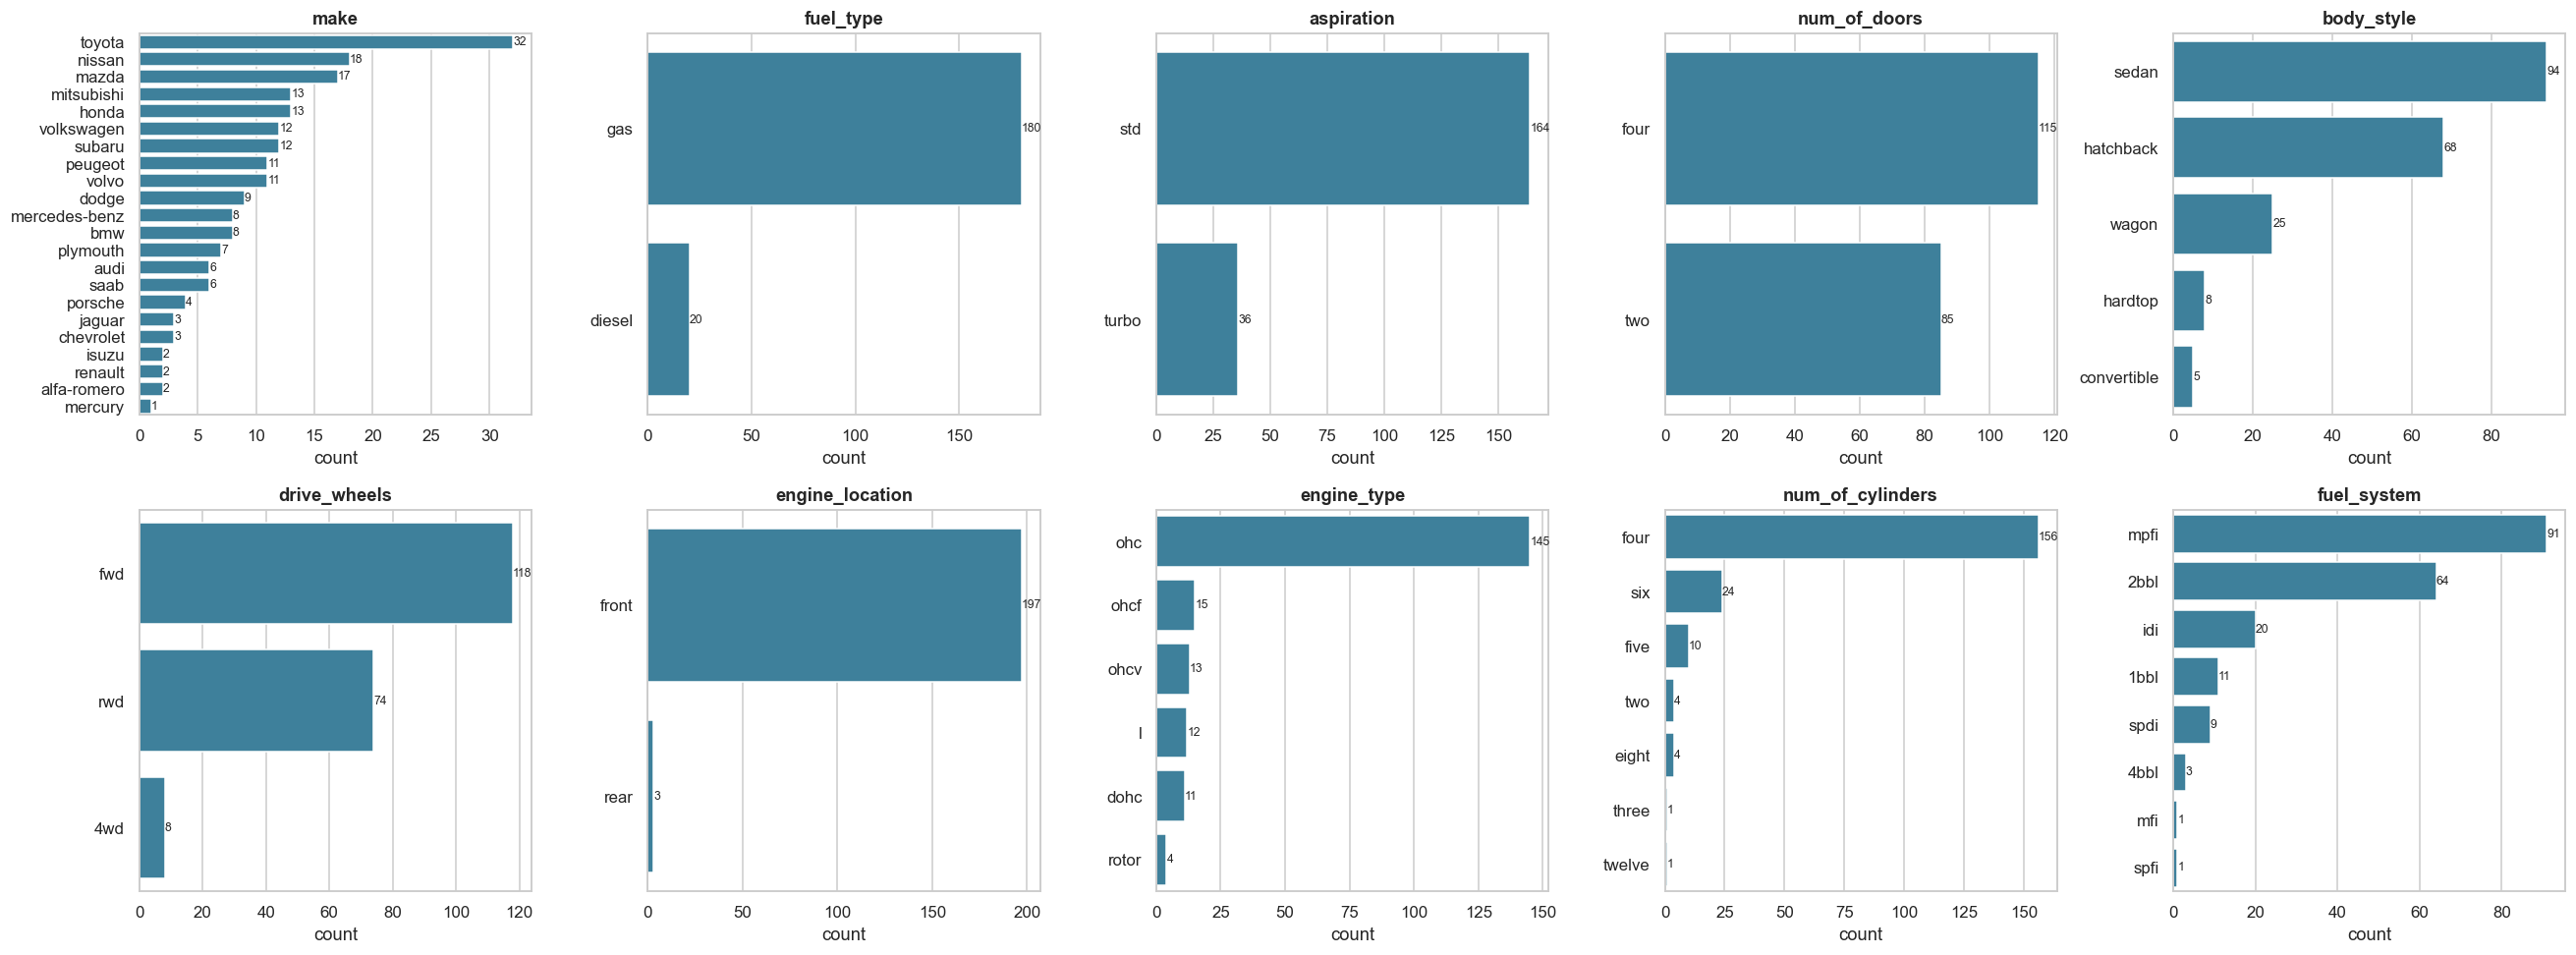

In [19]:
cat_features = ['make', 'fuel_type', 'aspiration', 'num_of_doors', 'body_style', 'drive_wheels',
                'engine_location', 'engine_type', 'num_of_cylinders', 'fuel_system']

fig, axes = plt.subplots(2, 5, figsize=(24, 9))
for ax, col in zip(axes.flatten(), cat_features):
    order = clean[col].value_counts().index
    sns.countplot(data=clean, y=col, order=order, ax=ax, color=ACCENT)
    ax.set_title(col); ax.set_ylabel('')
    for p in ax.patches:
        ax.annotate(int(p.get_width()), (p.get_width(), p.get_y() + p.get_height() / 2),
                    va='center', ha='left', fontsize=8)
plt.tight_layout(); plt.show()

In [20]:
# Rare categories matter: a level with only a handful of cars cannot support a reliable estimate.
rare = []
for col in cat_features:
    vc = clean[col].value_counts()
    for lvl, n in vc[vc <= 5].items():
        rare.append({'feature': col, 'level': lvl, 'count': n})
pd.DataFrame(rare)

,feature,level,count
0,make,porsche,4
1,make,jaguar,3
2,make,chevrolet,3
3,make,isuzu,2
4,make,renault,2
5,make,alfa-romero,2
6,make,mercury,1
7,body_style,convertible,5
8,engine_location,rear,3
9,engine_type,rotor,4


**Insights — Categorical distributions**
- The sample is dominated by one typical car: gas (180 of 200), standard aspiration (164), front engine (197), four-cylinder (156), `ohc` engine (145), mostly front-wheel drive (118) and sedans or hatchbacks (162 combined).
- Toyota is the largest make (32 cars), followed by Nissan (18) and Mazda (17).
- Rare levels make averages unstable: rear-engine (3), rotor engines (4), three- and twelve-cylinder cars (1 each), fuel systems `mfi` and `spfi` (1 each), and seven makes with fewer than 5 cars (Jaguar, Porsche, Mercury, Alfa Romeo, Renault, Isuzu, Chevrolet).
- Read every average price in the following sections together with its sample size.


## 07. Outlier Analysis

In [21]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < lo) | (s > hi)).sum(), lo, hi

rows = []
for col in num_features + ['price']:
    n, lo, hi = iqr_outliers(clean[col])
    rows.append({'feature': col, 'outliers': n, 'outlier_%': round(n / len(clean) * 100, 1),
                 'lower_fence': lo, 'upper_fence': hi})
outlier_df = pd.DataFrame(rows).sort_values('outliers', ascending=False)
outlier_df

,feature,outliers,outlier_%,lower_fence,upper_fence
8,compression_ratio,27,13.50,7.34,10.64
7,stroke,24,12.00,2.68,3.85
15,price,14,7.00,"-5,313.62","29,589.38"
2,width,11,5.50,60.42,70.42
5,engine_size,10,5.00,31.38,208.38
9,horsepower,5,2.50,1.00,185.00
0,wheel_base,3,1.50,82.65,114.25
12,highway_mpg,3,1.50,11.50,47.50
10,peak_rpm,2,1.00,"3,750.00","6,550.00"
11,city_mpg,2,1.00,2.50,46.50


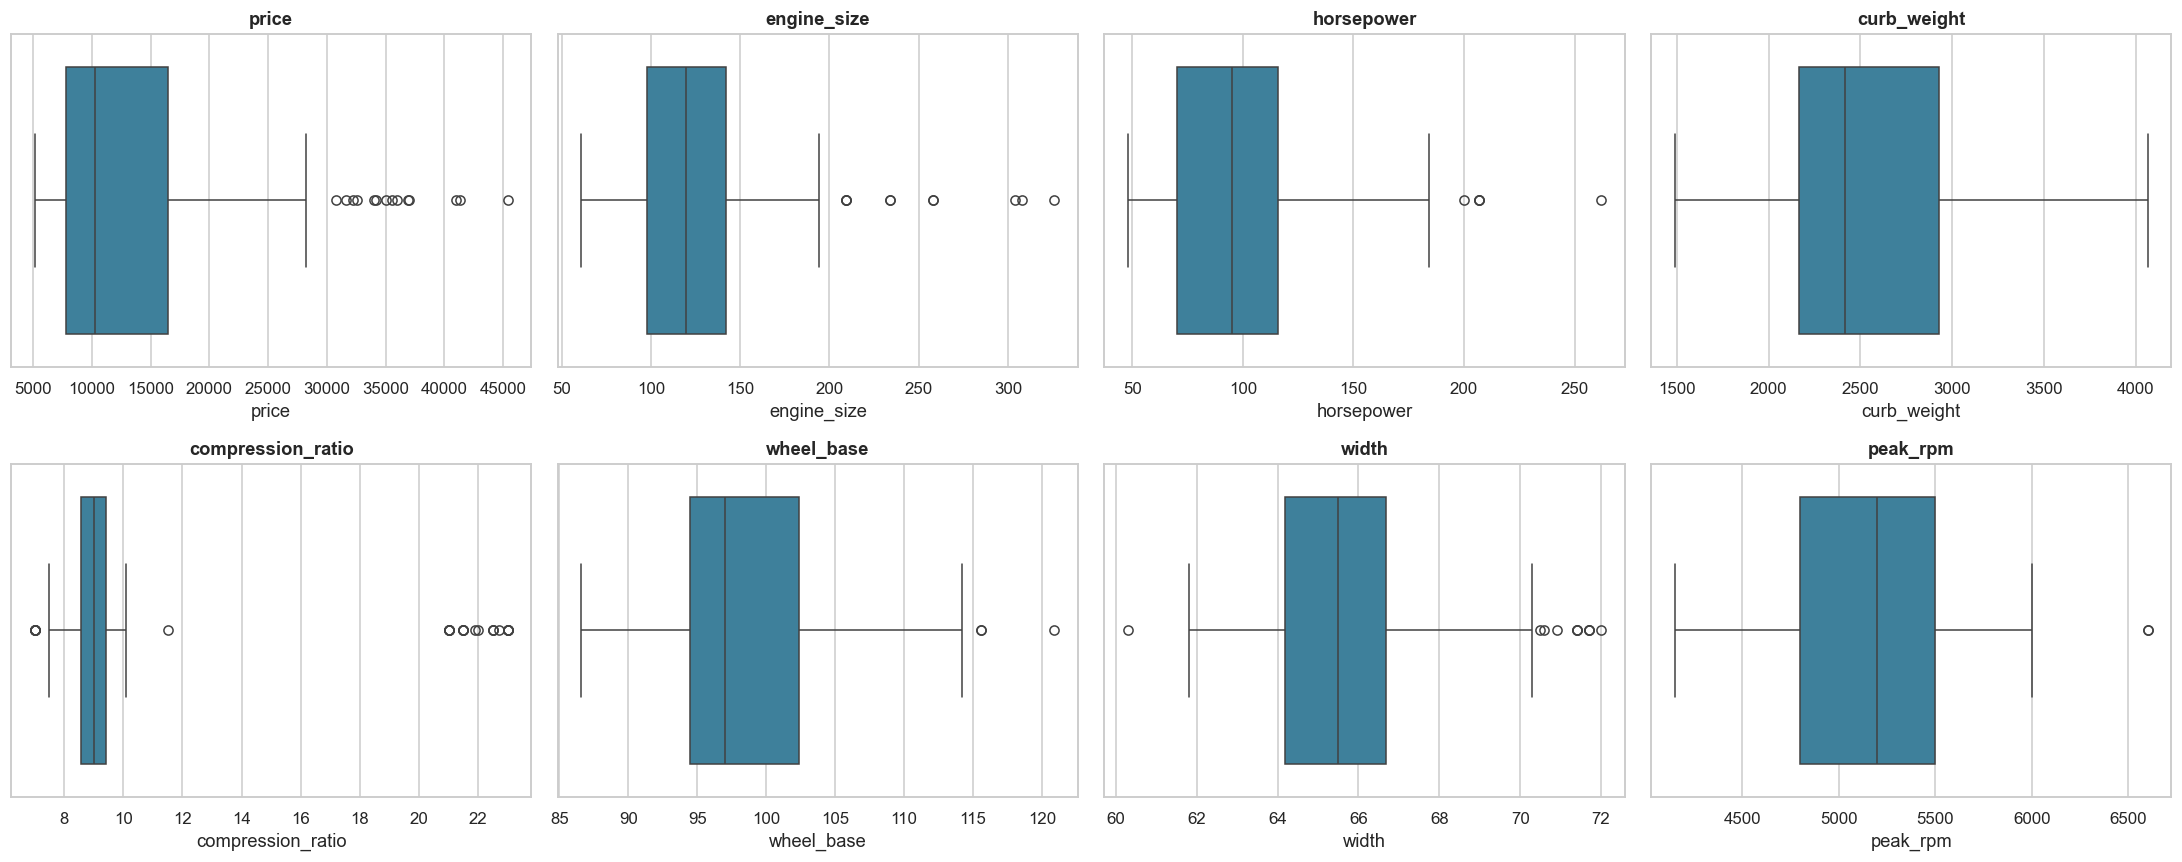

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flatten(), ['price', 'engine_size', 'horsepower', 'curb_weight',
                                     'compression_ratio', 'wheel_base', 'width', 'peak_rpm']):
    sns.boxplot(x=clean[col], ax=ax, color=ACCENT); ax.set_title(col)
plt.tight_layout(); plt.show()

In [23]:
# Who ARE the outliers? Outliers that are real high-end cars should be kept, not deleted.
hp_hi = iqr_outliers(clean['horsepower'])[2]
es_hi = iqr_outliers(clean['engine_size'])[2]
pr_hi = iqr_outliers(clean['price'])[2]
flag = (clean.horsepower > hp_hi) | (clean.engine_size > es_hi) | (clean.price > pr_hi)
print(f"Cars flagged as an outlier on price, engine_size or horsepower: {flag.sum()}")
clean.loc[flag, ['make', 'body_style', 'engine_size', 'horsepower', 'curb_weight', 'price']].sort_values('price', ascending=False)

Cars flagged as an outlier on price, engine_size or horsepower: 15


,make,body_style,engine_size,horsepower,curb_weight,price
70,mercedes-benz,hardtop,304,184.00,3715,45400
14,bmw,sedan,209,182.00,3380,41315
69,mercedes-benz,sedan,308,184.00,3900,40960
124,porsche,convertible,194,207.00,2800,37028
15,bmw,sedan,209,182.00,3505,36880
45,jaguar,sedan,326,262.00,3950,36000
44,jaguar,sedan,258,176.00,4066,35550
68,mercedes-benz,convertible,234,155.00,3685,35056
67,mercedes-benz,sedan,234,155.00,3740,34184
123,porsche,hardtop,194,207.00,2756,34028


**Outlier verdict:** the extreme values are concentrated in a small group of high-end marques (Jaguar, Mercedes-Benz, Porsche, BMW) with large engines and high horsepower. (The one exception is a 200 hp Nissan hatchback, a high-output performance variant at a mid price.) These are *genuine* premium vehicles, not data errors, and they are exactly the cars a price model most needs to understand. They should be **kept**, with the log-target and tree-based or regularised models used to handle their leverage — rather than being deleted.

## 08. Numeric Features vs Price

In [24]:
corr_cols = num_features + ['price']
pearson = clean[corr_cols].corr()['price'].drop('price')
spearman = clean[corr_cols].corr(method='spearman')['price'].drop('price')
logp = np.log(clean['price'])
pearson_log = clean[num_features].corrwith(logp)

corr_table = pd.DataFrame({'Pearson': pearson, 'Spearman': spearman, 'Pearson vs log(price)': pearson_log})
corr_table = corr_table.reindex(corr_table['Pearson'].abs().sort_values(ascending=False).index)
corr_table

,Pearson,Spearman,Pearson vs log(price)
engine_size,0.87,0.83,0.83
curb_weight,0.83,0.91,0.89
horsepower,0.81,0.85,0.83
width,0.75,0.82,0.80
highway_mpg,-0.71,-0.83,-0.78
length,0.69,0.81,0.78
city_mpg,-0.69,-0.83,-0.77
wheel_base,0.59,0.69,0.64
bore,0.54,0.65,0.61
height,0.14,0.27,0.18


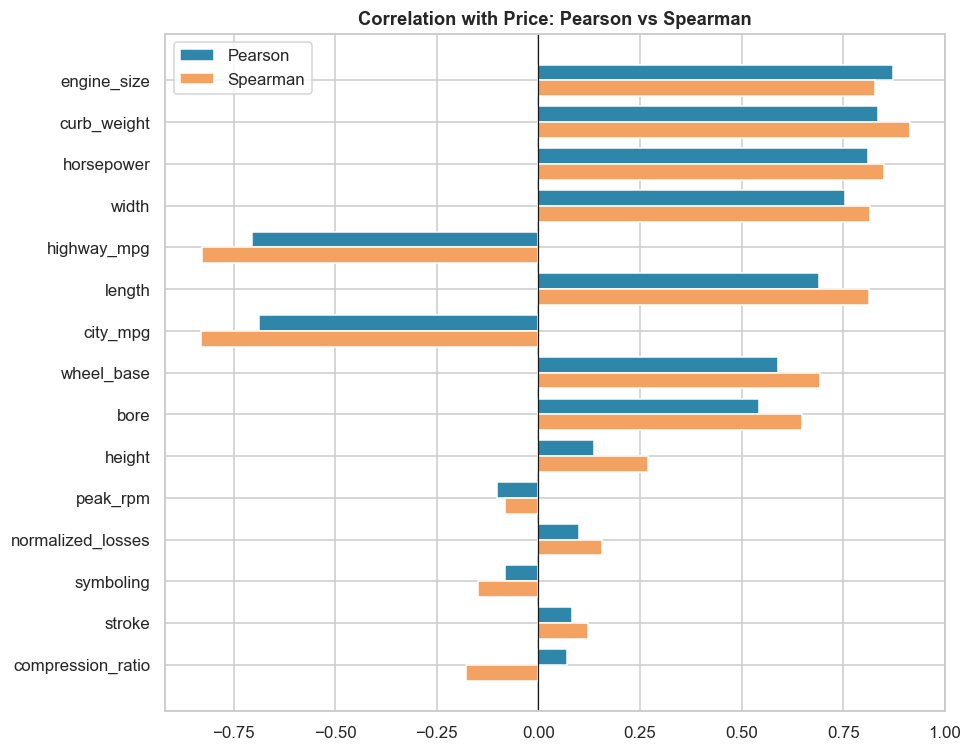

In [25]:
fig, ax = plt.subplots(figsize=(9, 7))
order = corr_table.index[::-1]
y = np.arange(len(order)); h = 0.38
ax.barh(y + h/2, corr_table.loc[order, 'Pearson'], h, label='Pearson', color=ACCENT)
ax.barh(y - h/2, corr_table.loc[order, 'Spearman'], h, label='Spearman', color='#F4A261')
ax.set_yticks(y); ax.set_yticklabels(order); ax.axvline(0, color='k', lw=.8)
ax.set_title('Correlation with Price: Pearson vs Spearman'); ax.legend()
plt.tight_layout(); plt.show()

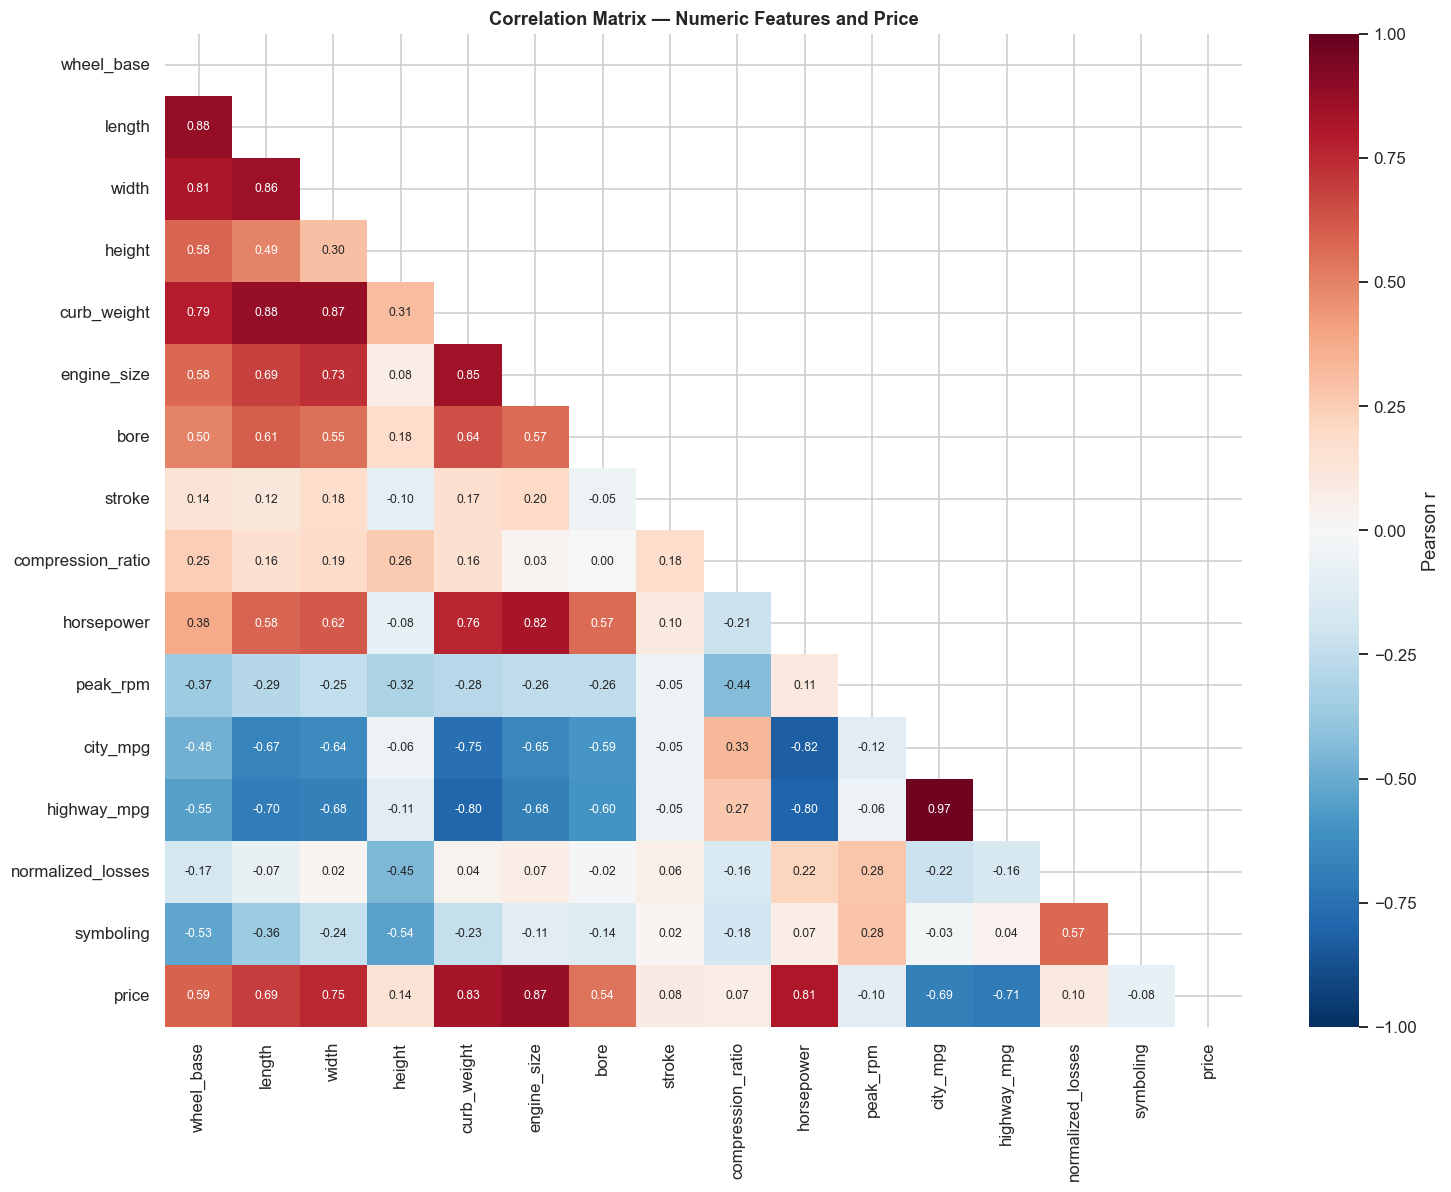

In [26]:
mask = np.triu(np.ones((len(corr_cols), len(corr_cols)), dtype=bool))
plt.figure(figsize=(14, 11))
sns.heatmap(clean[corr_cols].corr(), mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, annot_kws={'size': 8}, cbar_kws={'label': 'Pearson r'})
plt.title('Correlation Matrix — Numeric Features and Price')
plt.tight_layout(); plt.show()

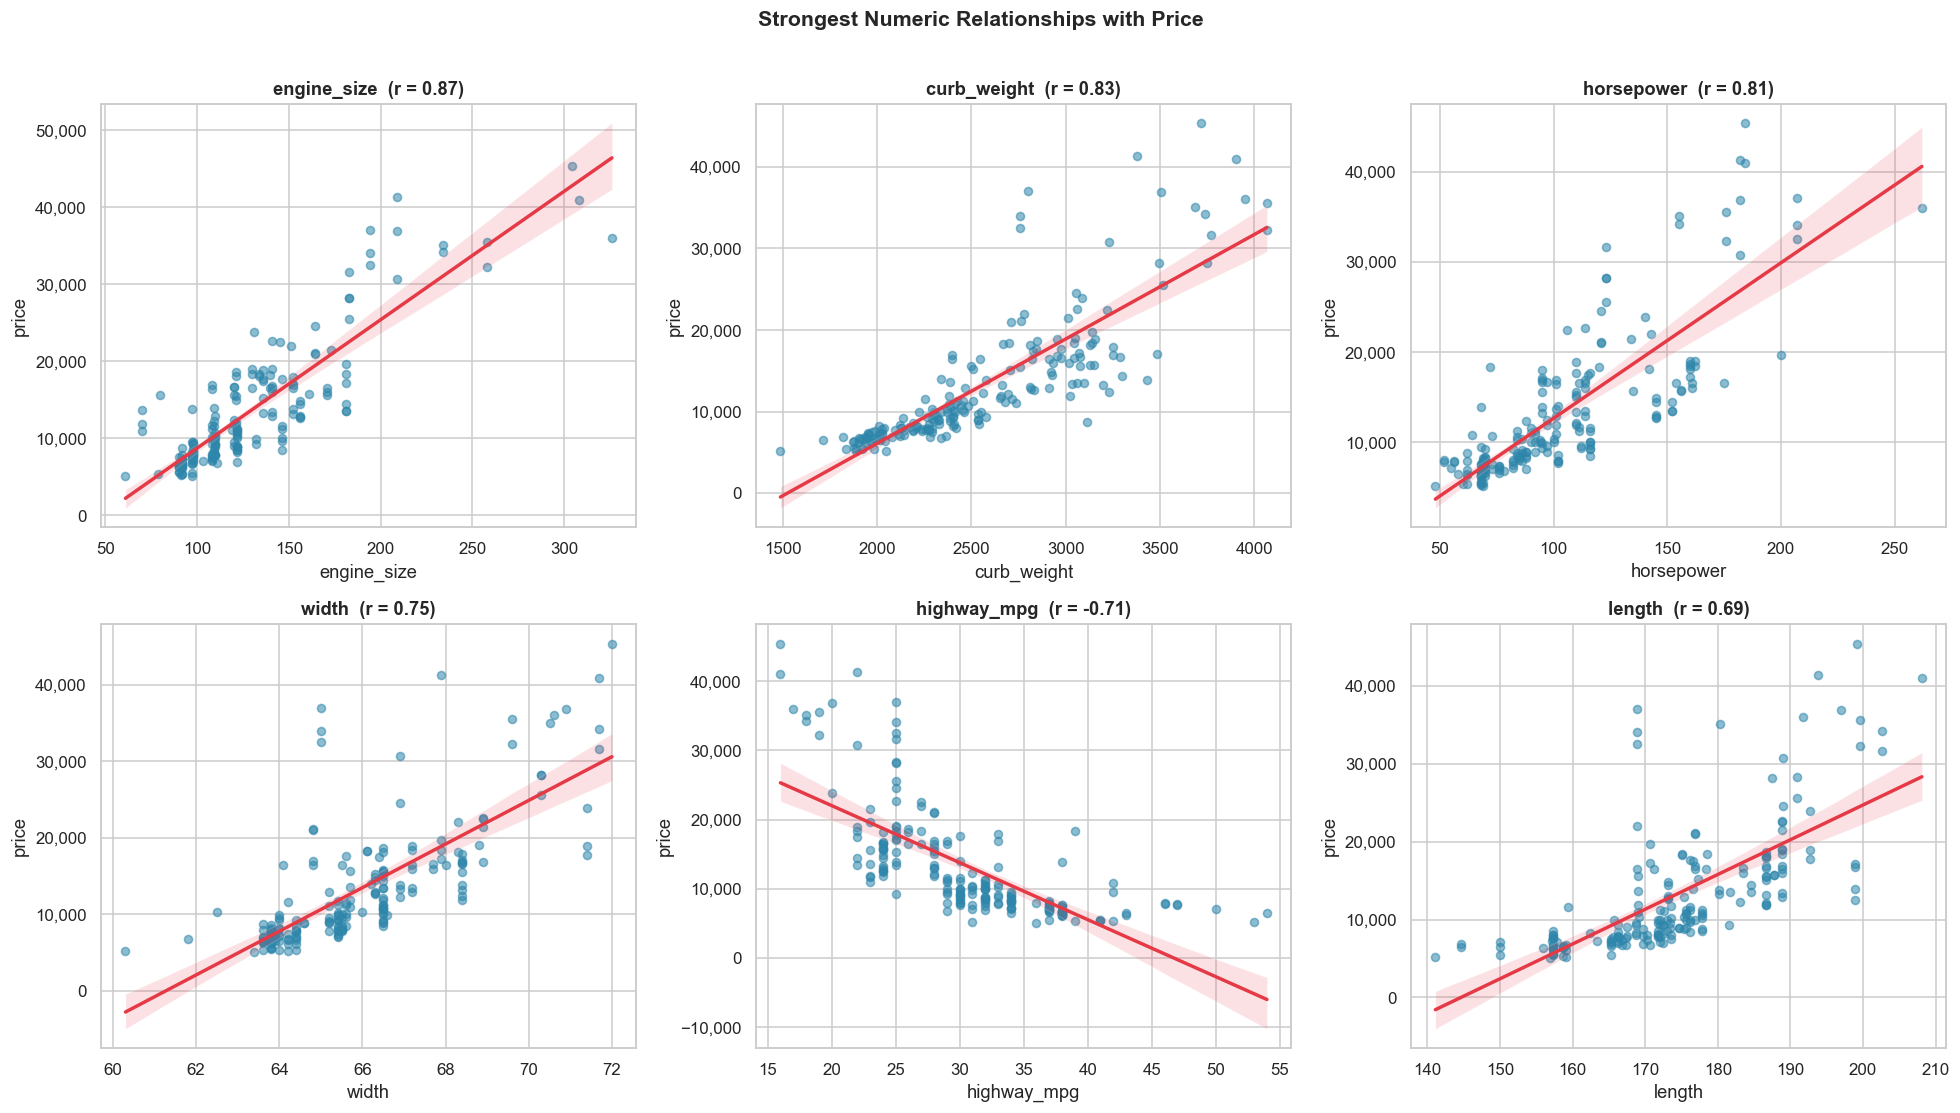

In [27]:
top6 = pearson.abs().sort_values(ascending=False).head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), top6):
    sns.regplot(data=clean, x=col, y='price', ax=ax, scatter_kws={'alpha': .55, 's': 28, 'color': ACCENT},
                line_kws={'color': HIGHLIGHT})
    ax.set_title(f"{col}  (r = {pearson[col]:.2f})")
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.suptitle('Strongest Numeric Relationships with Price', y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

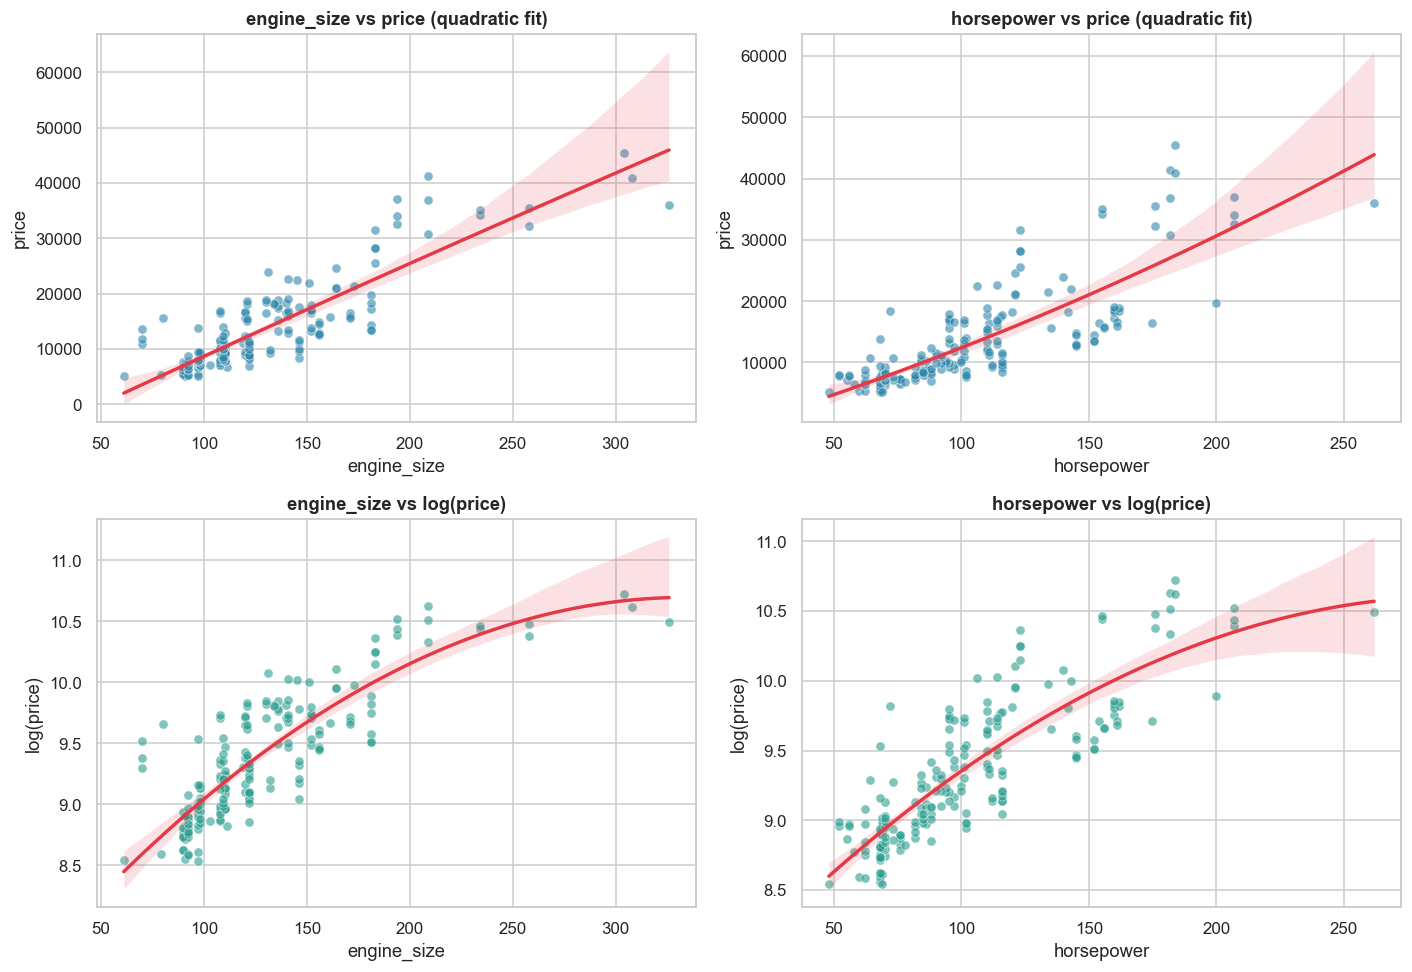

In [28]:
# Does the relationship look linear, or curved? Compare raw price vs log(price) for engine_size and horsepower.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for j, col in enumerate(['engine_size', 'horsepower']):
    sns.scatterplot(data=clean, x=col, y='price', ax=axes[0, j], color=ACCENT, alpha=.6)
    sns.regplot(data=clean, x=col, y='price', ax=axes[0, j], scatter=False, order=2, line_kws={'color': HIGHLIGHT})
    axes[0, j].set_title(f'{col} vs price (quadratic fit)')
    sns.scatterplot(x=clean[col], y=np.log(clean['price']), ax=axes[1, j], color='#2A9D8F', alpha=.6)
    sns.regplot(x=clean[col], y=np.log(clean['price']), ax=axes[1, j], scatter=False, order=2, line_kws={'color': HIGHLIGHT})
    axes[1, j].set_title(f'{col} vs log(price)'); axes[1, j].set_ylabel('log(price)')
plt.tight_layout(); plt.show()

**Reading the numerics:** engine size, curb weight, horsepower, width and length are strongly positively related to price, while city/highway MPG are strongly *negatively* related (efficient cars are small, cheap cars). The quadratic fits show the raw relationships bend upward at the high end — price grows faster than size/power — and the log-price version is visibly closer to a straight line. Spearman values are also high (0.8+ for the top features, and above Pearson for curb weight and MPG), which confirms the relationships are monotonic rather than driven by a few extreme points. Weak or near-zero relationships: height, peak RPM, normalized losses, symboling, stroke and compression ratio.

## 09. Categorical Features vs Price

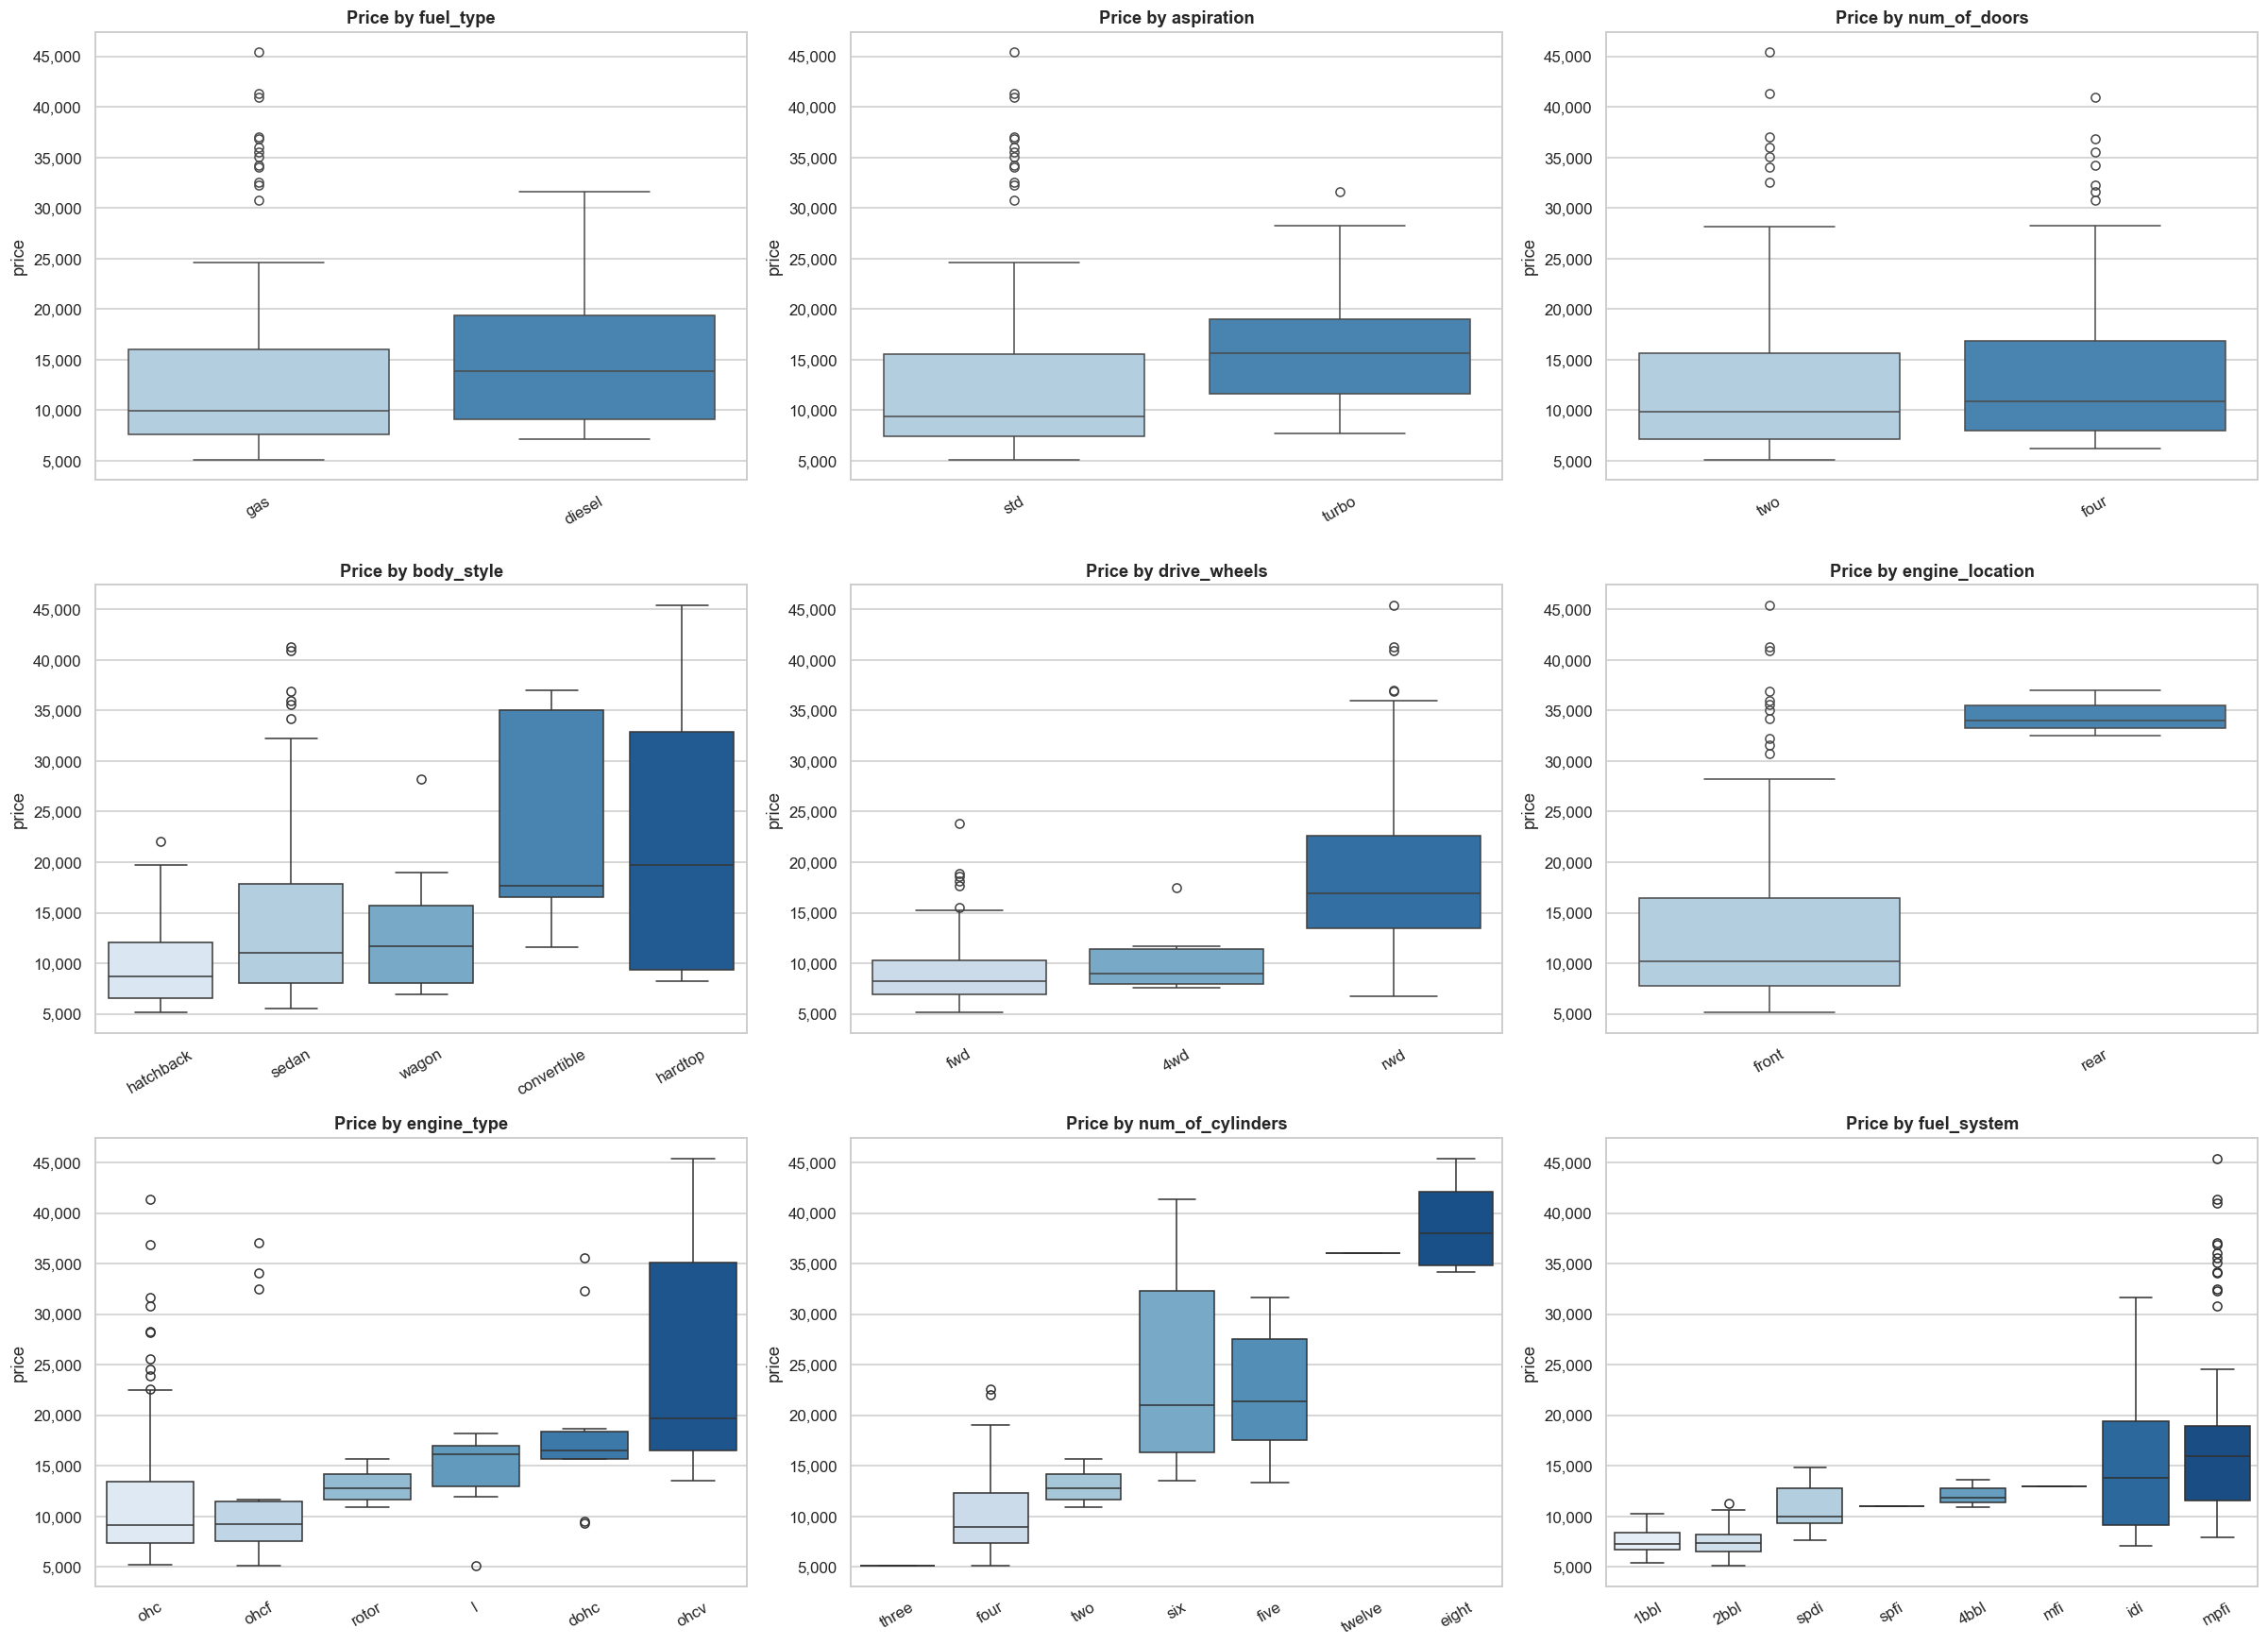

In [29]:
cat_vs_price = ['fuel_type', 'aspiration', 'num_of_doors', 'body_style', 'drive_wheels',
                'engine_location', 'engine_type', 'num_of_cylinders', 'fuel_system']
fig, axes = plt.subplots(3, 3, figsize=(22, 16))
for ax, col in zip(axes.flatten(), cat_vs_price):
    order = clean.groupby(col)['price'].median().sort_values().index
    sns.boxplot(data=clean, x=col, y='price', order=order, ax=ax, palette='Blues')
    ax.set_title(f'Price by {col}'); ax.tick_params(axis='x', rotation=30); ax.set_xlabel('')
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout(); plt.show()

### Are the differences statistically real?

In [30]:
# Kruskal-Wallis (non-parametric, safe for skewed price) for significance, and eta-squared on log(price)
# as an effect size: the share of price variance each categorical explains ON ITS OWN.
def eta_squared(groups_col, y):
    grand = y.mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for _, g in y.groupby(clean[groups_col]))
    ss_total = ((y - grand) ** 2).sum()
    return ss_between / ss_total

rows = []
for col in cat_features:
    groups = [g['price'].values for _, g in clean.groupby(col) if len(g) > 1]
    H, p = stats.kruskal(*groups)
    rows.append({'feature': col, 'levels': clean[col].nunique(), 'kruskal_H': H, 'p_value': p,
                 'eta_squared (log price)': eta_squared(col, np.log(clean['price']))})
cat_stats = pd.DataFrame(rows).sort_values('eta_squared (log price)', ascending=False)
cat_stats['significant (p<0.05)'] = cat_stats['p_value'] < 0.05
cat_stats

,feature,levels,kruskal_H,p_value,eta_squared (log price),significant (p<0.05)
0,make,22,122.12,0.00,0.72,True
8,num_of_cylinders,7,76.45,0.00,0.53,True
9,fuel_system,8,120.71,0.00,0.52,True
5,drive_wheels,3,92.62,0.00,0.47,True
7,engine_type,6,37.57,0.00,0.20,True
4,body_style,5,25.00,0.00,0.15,True
6,engine_location,2,7.72,0.01,0.07,True
2,aspiration,2,18.86,0.00,0.07,True
1,fuel_type,2,4.21,0.04,0.02,True
3,num_of_doors,2,3.60,0.06,0.01,False


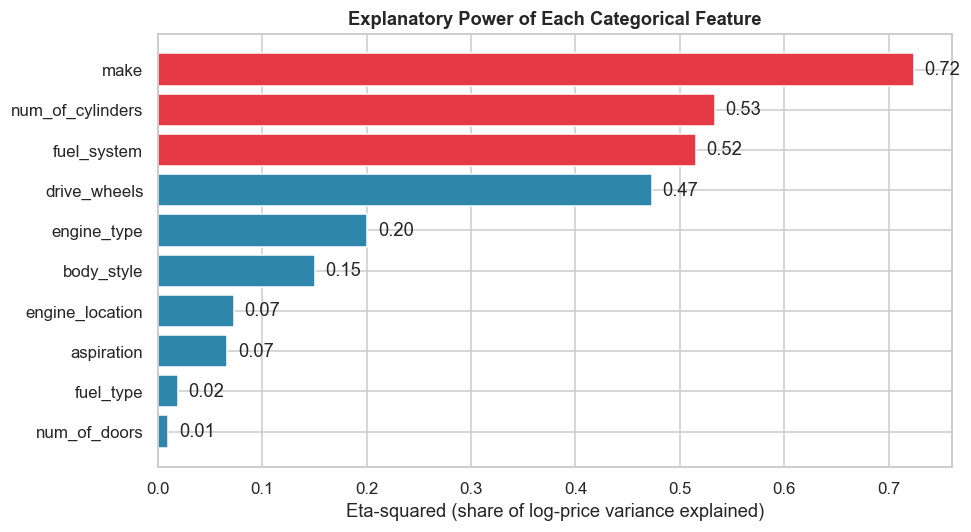

In [31]:
fig, ax = plt.subplots(figsize=(9, 5))
d = cat_stats.sort_values('eta_squared (log price)')
colors = [HIGHLIGHT if v > .5 else ACCENT for v in d['eta_squared (log price)']]
ax.barh(d['feature'], d['eta_squared (log price)'], color=colors)
for i, v in enumerate(d['eta_squared (log price)']):
    ax.text(v + .01, i, f'{v:.2f}', va='center')
ax.set_xlabel('Eta-squared (share of log-price variance explained)')
ax.set_title('Explanatory Power of Each Categorical Feature')
plt.tight_layout(); plt.show()

**Caution on `make`:** it has 21 levels for 200 rows (roughly 9 cars per brand), so a high eta-squared is partly mechanical — more levels can always soak up more variance. It still tells us brand is a major price signal, but it is also the feature most at risk of overfitting. This is revisited in the modelling-readiness plan.

In [32]:
# Engine configuration: price by cylinders, engine type and fuel system (with sample sizes)
for col in ['num_of_cylinders', 'engine_type', 'fuel_system']:
    t = (clean.groupby(col)['price'].agg(vehicle_count='count', median_price='median', average_price='mean')
              .sort_values('median_price', ascending=False))
    t['reliable (n>=5)'] = np.where(t['vehicle_count'] >= 5, 'yes', 'no')
    print(f"PRICE BY {col.upper()}")
    display(t.round(0))

PRICE BY NUM_OF_CYLINDERS


,vehicle_count,median_price,average_price,reliable (n>=5)
num_of_cylinders,,,,
eight,4,"38,008.00","38,900.00",no
twelve,1,"36,000.00","36,000.00",no
five,10,"21,398.00","22,008.00",yes
six,24,"21,038.00","23,672.00",yes
two,4,"12,745.00","13,020.00",no
four,156,"8,948.00","10,283.00",yes
three,1,"5,151.00","5,151.00",no


PRICE BY ENGINE_TYPE


,vehicle_count,median_price,average_price,reliable (n>=5)
engine_type,,,,
ohcv,13,"19,699.00","25,098.00",yes
dohc,11,"16,500.00","18,537.00",yes
l,12,"16,105.00","14,628.00",yes
rotor,4,"12,745.00","13,020.00",no
ohcf,15,"9,233.00","13,739.00",yes
ohc,145,"9,095.00","11,567.00",yes


PRICE BY FUEL_SYSTEM


,vehicle_count,median_price,average_price,reliable (n>=5)
fuel_system,,,,
mpfi,91,"15,985.00","17,650.00",yes
idi,20,"13,852.00","15,838.00",yes
mfi,1,"12,964.00","12,964.00",no
4bbl,3,"11,845.00","12,145.00",no
spfi,1,"11,048.00","11,048.00",no
spdi,9,"9,959.00","10,990.00",yes
2bbl,64,"7,324.00","7,433.00",yes
1bbl,11,"7,295.00","7,556.00",yes


**Insights — Price by category and engine configuration**
- Every categorical feature except door count (p = 0.054) shows a statistically significant price difference (Kruskal–Wallis). Make is the strongest (eta² 0.72), followed by cylinders, fuel system and drive wheels.
- Engine configuration separates price tiers: eight-, five- and six-cylinder cars have medians of about 38,008, 21,398 and 21,038, versus 8,949 for four-cylinder cars (156 of the 200). By engine type, `ohcv` (19,699) and `dohc` (16,500) are far above the common `ohc` (9,095).
- Fuel system largely reflects car class: `mpfi` cars have a median of 15,985 versus 7,324 for `2bbl`.
- Diesels have a higher median than gas cars (13,853 vs 9,989), but only because 13 of the 20 diesels are turbocharged. Diesel-standard cars (7) have a median of 7,898, so aspiration, not fuel type, explains the gap.
- Treat these as descriptive: engine type, fuel system and cylinders overlap with engine size and car class.


## 10. Brand Analysis

In [33]:
brand = clean.groupby('make').agg(cars=('price', 'size'), median_price=('price', 'median'),
                                  mean_price=('price', 'mean'), avg_hp=('horsepower', 'mean'),
                                  avg_engine=('engine_size', 'mean')).sort_values('median_price', ascending=False)
brand['tier'] = pd.cut(brand['median_price'], bins=[0, 9000, 17000, np.inf],
                       labels=['Economy', 'Mid-market', 'Premium'])
brand

,cars,median_price,mean_price,avg_hp,avg_engine,tier
make,,,,,,
jaguar,3,"35,550.00","34,600.00",204.67,280.67,Premium
porsche,4,"33,278.00","31,400.50",191.00,183.25,Premium
mercedes-benz,8,"32,892.00","33,647.00",146.25,226.50,Premium
bmw,8,"22,835.00","26,118.75",138.88,166.88,Premium
volvo,11,"18,420.00","18,063.18",128.00,142.27,Premium
audi,6,"17,580.00","17,859.17",114.50,130.67,Premium
peugeot,11,"16,630.00","15,489.09",99.82,135.82,Mid-market
mercury,1,"16,503.00","16,503.00",175.00,140.00,Mid-market
alfa-romero,2,"16,500.00","16,500.00",132.50,141.00,Mid-market


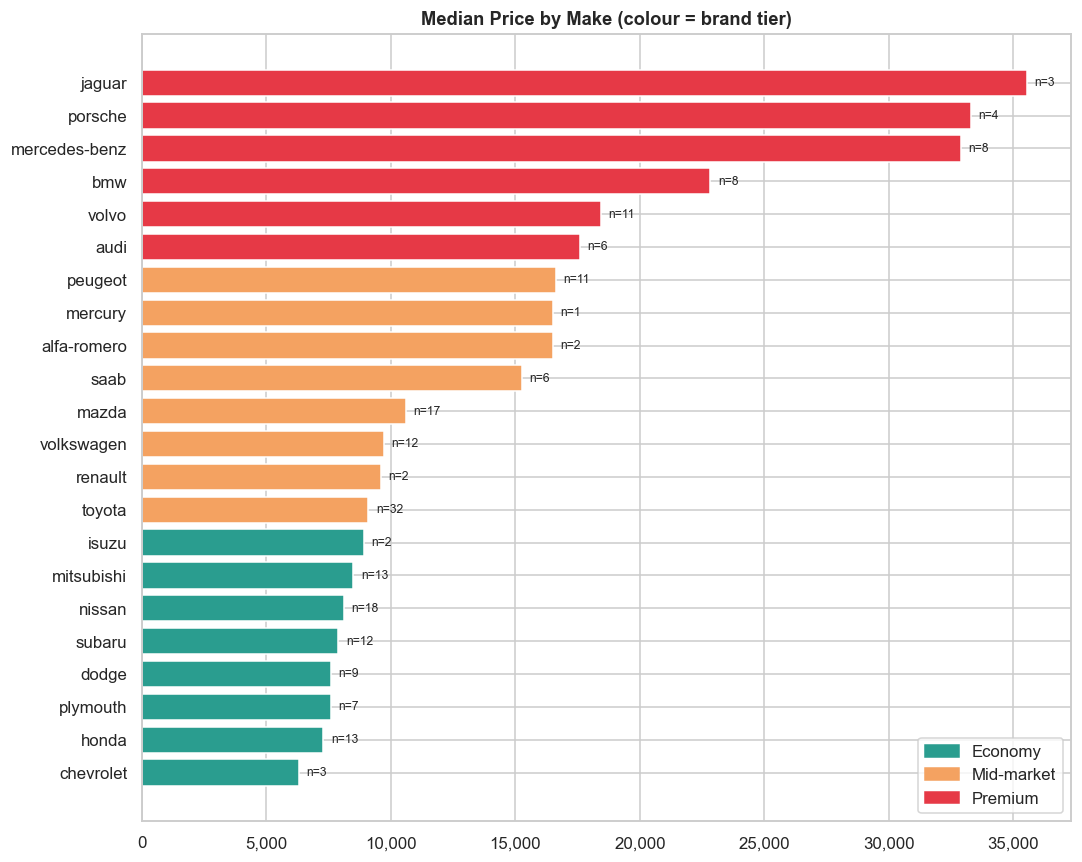

In [34]:
tier_colors = {'Economy': '#2A9D8F', 'Mid-market': '#F4A261', 'Premium': HIGHLIGHT}
b = brand.sort_values('median_price')
fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(b.index, b['median_price'], color=[tier_colors[t] for t in b['tier']])
for bar, n in zip(bars, b['cars']):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height()/2, f'n={n}', va='center', fontsize=8)
ax.set_title('Median Price by Make (colour = brand tier)')
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=t) for t, c in tier_colors.items()], loc='lower right')
plt.tight_layout(); plt.show()

Specs-only model (engine_size + curb_weight + horsepower, in-sample) explains 85.3% of log-price variance.


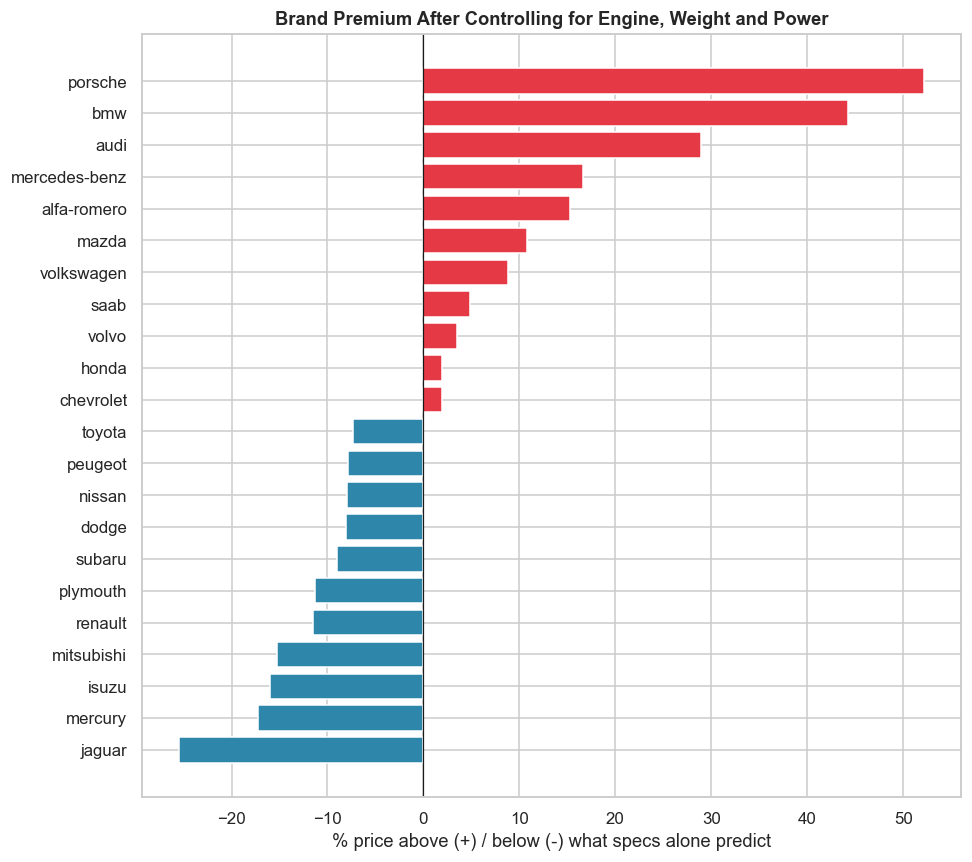

In [35]:
# Brand premium: does a brand cost more than its SPECS justify?
# Fit a simple specs-only line (log price ~ engine_size + curb_weight + horsepower) and look at residuals by make.
X = clean[['engine_size', 'curb_weight', 'horsepower']]
X = (X - X.mean()) / X.std()
A = np.c_[np.ones(len(X)), X.values]
coef, *_ = np.linalg.lstsq(A, np.log(clean['price']), rcond=None)
clean['specs_only_resid'] = np.log(clean['price']) - A @ coef
r2 = 1 - clean['specs_only_resid'].var() / np.log(clean['price']).var()
print(f"Specs-only model (engine_size + curb_weight + horsepower, in-sample) explains {r2*100:.1f}% of log-price variance.")

prem = clean.groupby('make')['specs_only_resid'].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(prem.index, (np.exp(prem.values) - 1) * 100, color=[HIGHLIGHT if v > 0 else ACCENT for v in prem.values])
ax.axvline(0, color='k', lw=.8)
ax.set_xlabel('% price above (+) / below (-) what specs alone predict')
ax.set_title('Brand Premium After Controlling for Engine, Weight and Power')
plt.tight_layout(); plt.show()

,cars,median_price,reliable (n>=5)
make,,,
jaguar,3,"35,550.00",no
porsche,4,"33,278.00",no
mercedes-benz,8,"32,892.00",yes
bmw,8,"22,835.00",yes
volvo,11,"18,420.00",yes
audi,6,"17,580.00",yes
peugeot,11,"16,630.00",yes
mercury,1,"16,503.00",no
alfa-romero,2,"16,500.00",no


Top-10 makes by median price that have fewer than 5 cars: ['jaguar', 'porsche', 'mercury', 'alfa-romero']  -> their rank rests on 1-4 cars
Makes with fewer than 5 cars overall: ['jaguar', 'porsche', 'mercury', 'alfa-romero', 'renault', 'isuzu', 'chevrolet']


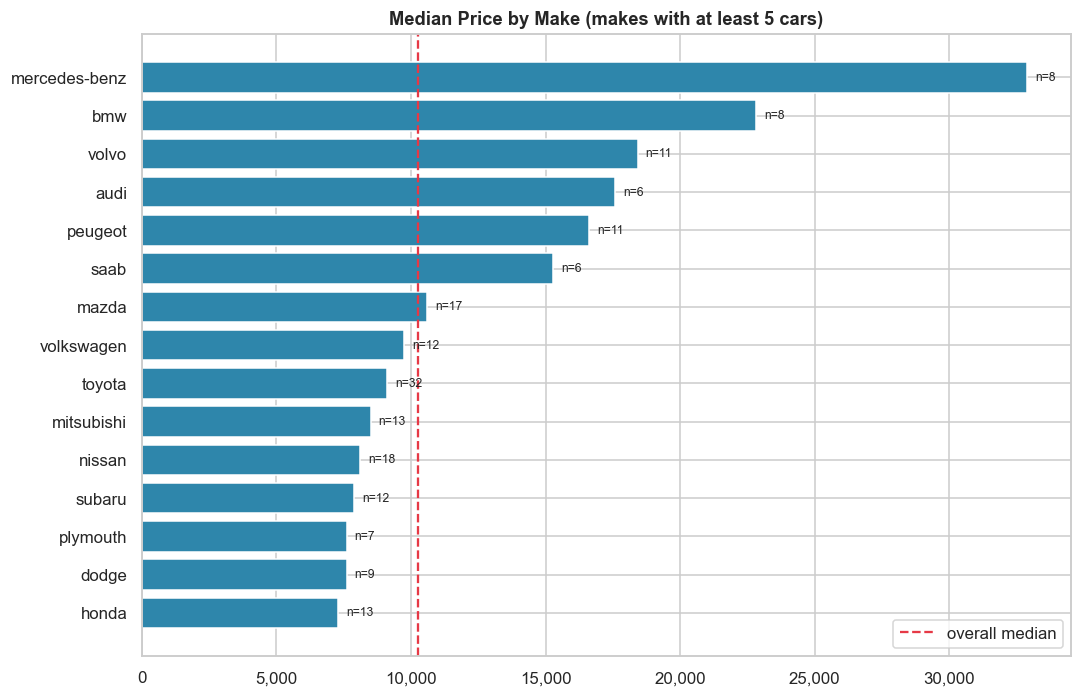

In [36]:
# Manufacturer ranking WITH a sample-size check
rank = brand[['cars', 'median_price']].copy()
rank['reliable (n>=5)'] = np.where(rank['cars'] >= 5, 'yes', 'no')
top10 = rank.head(10)
display(top10)
unstable = top10[top10['cars'] < 5].index.tolist()
print(f"Top-10 makes by median price that have fewer than 5 cars: {unstable}  -> their rank rests on 1-4 cars")
print(f"Makes with fewer than 5 cars overall: {rank[rank['cars'] < 5].index.tolist()}")

reliable = rank[rank['cars'] >= 5].sort_values('median_price')
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(reliable.index, reliable['median_price'], color=ACCENT)
for i, (m, r) in enumerate(reliable.iterrows()):
    ax.text(r['median_price'] + 300, i, f"n={int(r['cars'])}", va='center', fontsize=8)
ax.axvline(clean['price'].median(), color=HIGHLIGHT, ls='--', label='overall median')
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}')); ax.legend(loc='lower right')
ax.set_title('Median Price by Make (makes with at least 5 cars)')
plt.tight_layout(); plt.show()

**Insights — Brand**
- Jaguar, Porsche, Mercedes-Benz and BMW sit at the top (medians 22.8K to 35.6K); Honda, Chevrolet, Plymouth and Dodge sit at the bottom (6.3K to 7.6K).
- A ranking by median needs a sample-size check: four of the top ten by median have fewer than 5 cars (Jaguar 3, Porsche 4, Alfa Romeo 2, Mercury 1), so their positions rest on very little data. The chart above ranks only makes with at least 5 cars.
- After controlling for engine size, weight and power, Porsche (+52%), BMW (+44%) and Audi (+29%) carry a genuine brand premium, while Jaguar's gap (−25%) rests on only 3 cars.


## 11. Multi-Dimensional Interactions

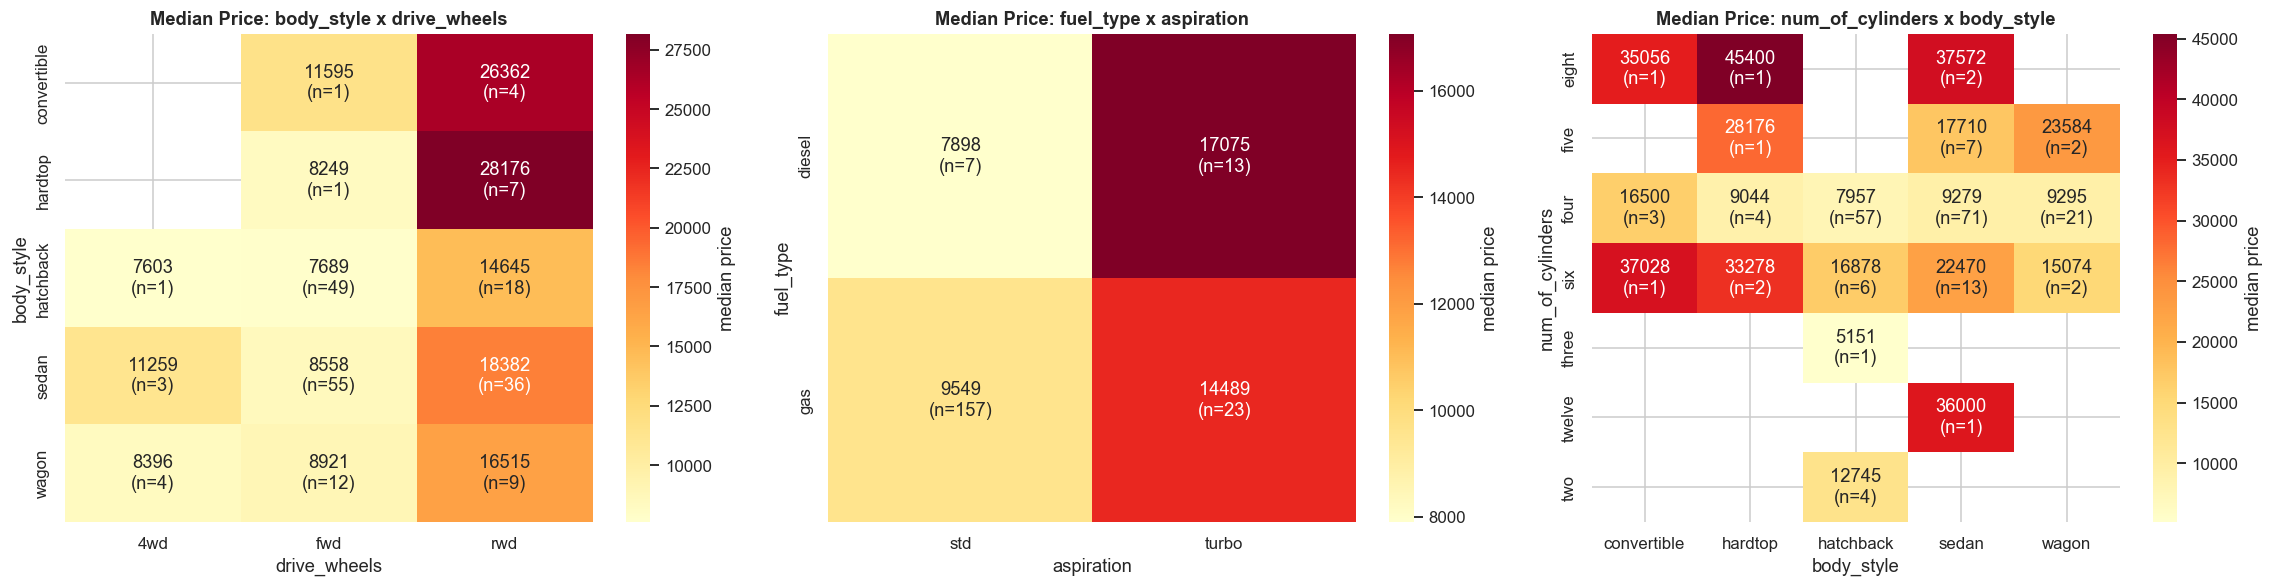

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, (r, c) in zip(axes, [('body_style', 'drive_wheels'), ('fuel_type', 'aspiration'), ('num_of_cylinders', 'body_style')]):
    pv = clean.pivot_table(index=r, columns=c, values='price', aggfunc='median')
    cnt = clean.pivot_table(index=r, columns=c, values='price', aggfunc='size')
    annot = pv.round(0).astype('Int64').astype(str) + '\n(n=' + cnt.fillna(0).astype(int).astype(str) + ')'
    annot = annot.where(pv.notna(), '')
    sns.heatmap(pv, annot=annot, fmt='', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'median price'})
    ax.set_title(f'Median Price: {r} x {c}')
plt.tight_layout(); plt.show()

Combinations present: 55 of 110 | with >= 3 cars: 30 (covering 171 of 200 cars)


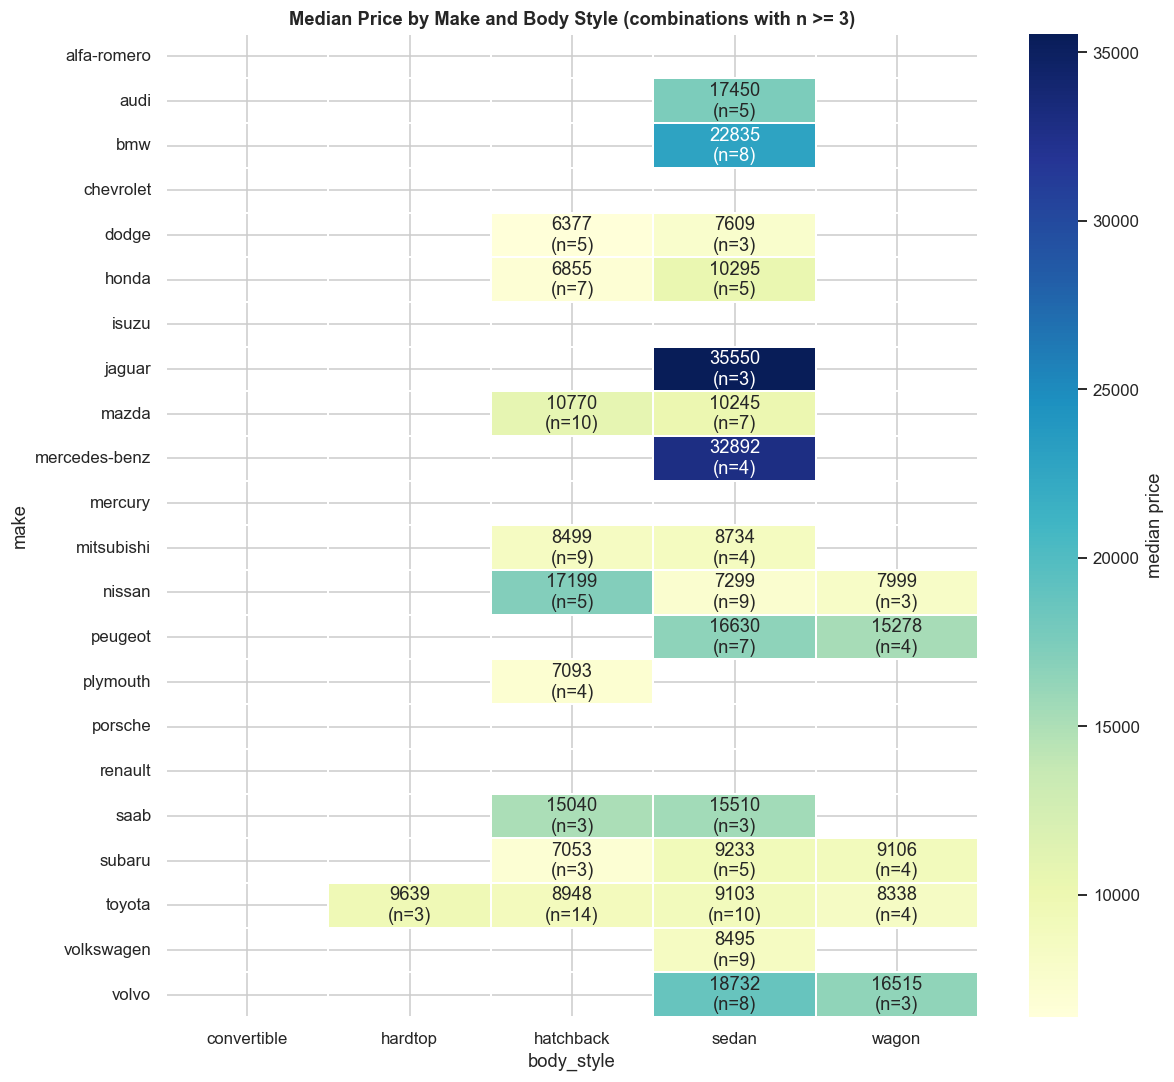

In [38]:
# Make x body style: median price, showing only combinations with at least 3 cars
mb_med = clean.pivot_table(index='make', columns='body_style', values='price', aggfunc='median')
mb_n = clean.pivot_table(index='make', columns='body_style', values='price', aggfunc='size')
mask = mb_n.isna() | (mb_n < 3)
annot = mb_med.round(0).astype('Int64').astype(str) + '\n(n=' + mb_n.fillna(0).astype(int).astype(str) + ')'
annot = annot.where(~mask, '')
print(f"Combinations present: {int(mb_n.notna().sum().sum())} of {mb_n.size} | with >= 3 cars: {int((mb_n >= 3).sum().sum())} "
      f"(covering {int(mb_n[mb_n >= 3].sum().sum())} of {len(clean)} cars)")
fig, ax = plt.subplots(figsize=(11, 10))
sns.heatmap(mb_med, mask=mask, annot=annot, fmt='', cmap='YlGnBu', linewidths=.3, ax=ax, cbar_kws={'label': 'median price'})
ax.set_title('Median Price by Make and Body Style (combinations with n >= 3)')
plt.tight_layout(); plt.show()

**Insights — Interactions**
- Drive wheels matter within each body style: rear-wheel-drive sedans have a median of 18,382 versus 8,558 for front-wheel-drive sedans, and rear-wheel hatchbacks 14,645 versus 7,689.
- Turbo adds a premium within both fuel types (gas 14,489 vs 9,549; diesel 17,075 vs 7,898, the latter from only 20 diesels).
- Within most makes, body style moves the median only a little (Toyota: 8,338 to 9,103 across four styles), while gaps between makes are large (Volvo sedans 18,732 vs Volkswagen sedans 8,495): brand outweighs body style.
- Nissan hatchbacks show why specs still matter within a make: the two four-cylinder cars sold for 7,799 and 8,949, the three six-cylinder cars (160–200 hp) for 17,199 to 19,699.
- The make × body-style grid is sparse: only 55 of 110 combinations exist and 30 have at least 3 cars (covering 171 of 200 cars). Use it to explore, not as a pricing table.


## 12. Engine, Performance and Efficiency

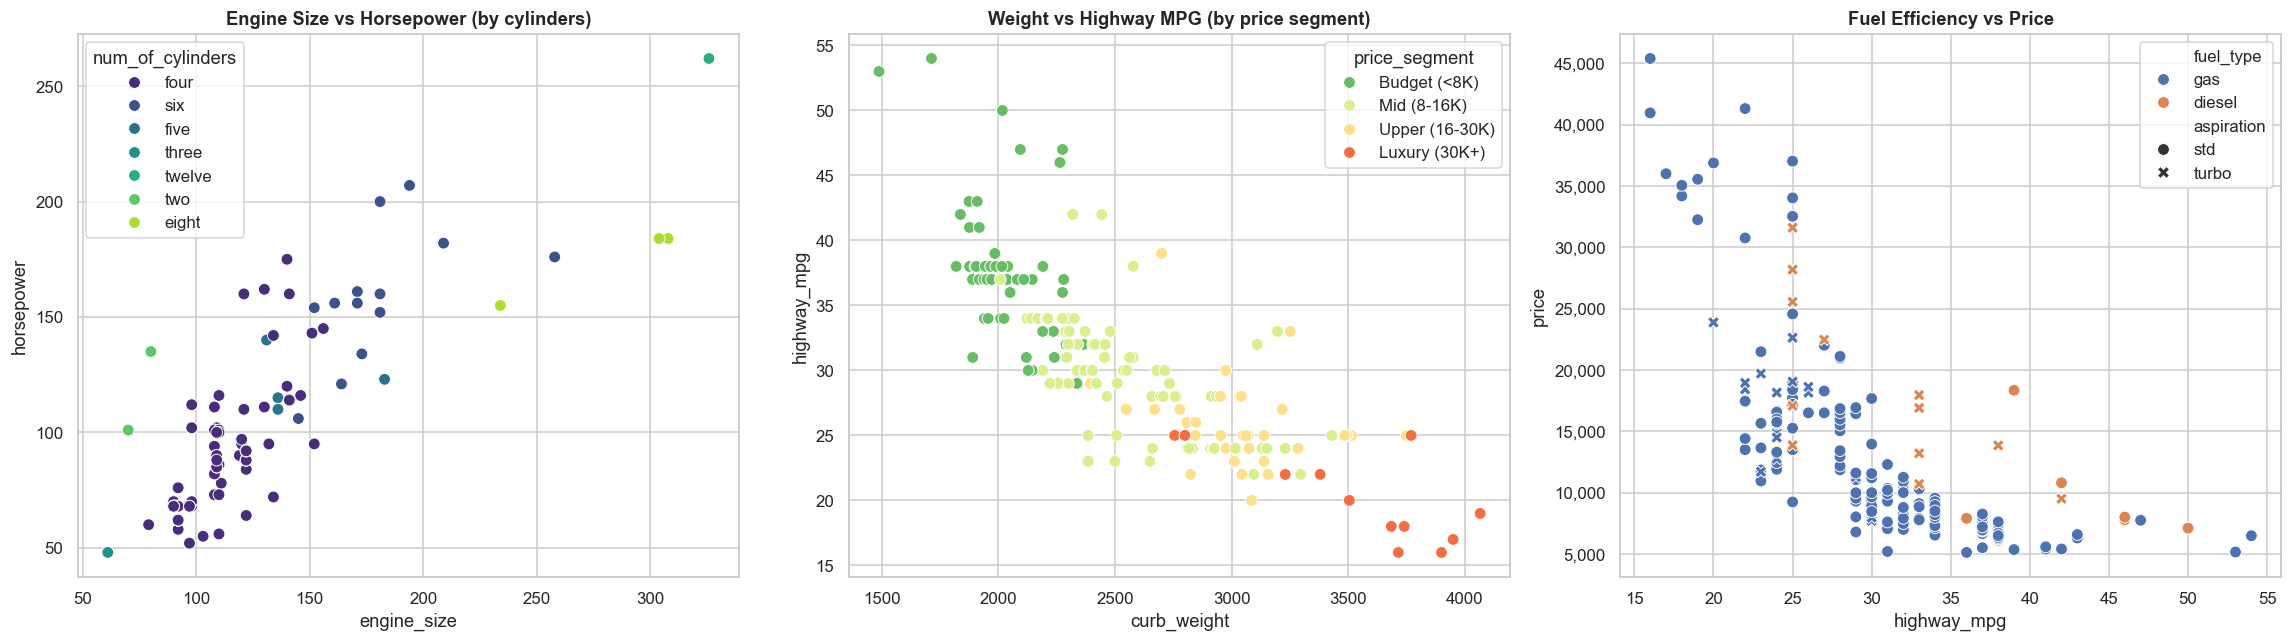

In [39]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
sns.scatterplot(data=clean, x='engine_size', y='horsepower', hue='num_of_cylinders', ax=axes[0], s=60, palette='viridis')
axes[0].set_title('Engine Size vs Horsepower (by cylinders)')
sns.scatterplot(data=clean, x='curb_weight', y='highway_mpg', hue='price_segment', ax=axes[1], s=60, palette='RdYlGn_r')
axes[1].set_title('Weight vs Highway MPG (by price segment)')
sns.scatterplot(data=clean, x='highway_mpg', y='price', hue='fuel_type', style='aspiration', ax=axes[2], s=60)
axes[2].set_title('Fuel Efficiency vs Price')
axes[2].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout(); plt.show()

In [40]:
# Diesel vs gas, turbo vs standard: price AND efficiency trade-offs
trade = clean.groupby(['fuel_type', 'aspiration']).agg(cars=('price', 'size'), median_price=('price', 'median'),
        avg_hp=('horsepower', 'mean'), avg_hwy_mpg=('highway_mpg', 'mean'), avg_weight=('curb_weight', 'mean'))
trade

cars  median_price  avg_hp  avg_hwy_mpg  avg_weight
fuel_type aspiration                                                     
diesel    std            7      7,898.00   58.14        43.71    2,319.29
          turbo         13     17,075.00   98.62        29.92    3,210.85
gas       std          157      9,549.00  100.66        30.94    2,484.70
          turbo         23     14,489.00  137.48        25.61    2,742.04

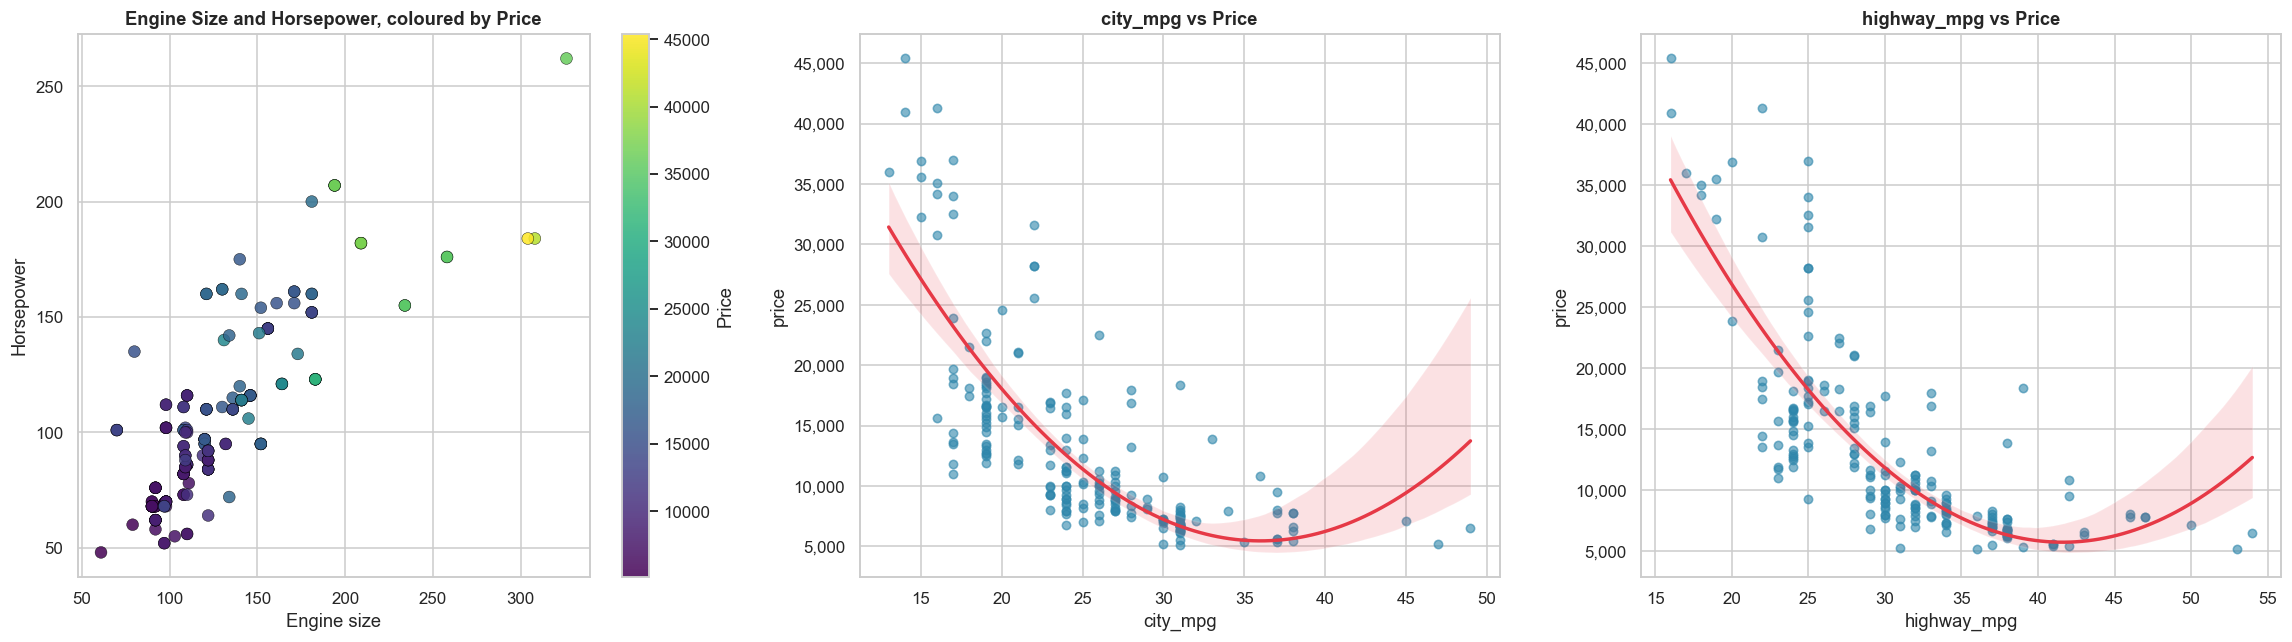

Correlation engine_size vs horsepower: 0.82


,city_mpg,highway_mpg,price
city_mpg,1.00,0.97,-0.69
highway_mpg,0.97,1.00,-0.70
price,-0.69,-0.70,1.00


In [41]:
# Horsepower x engine size coloured by price, and fuel efficiency vs price
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
sc = axes[0].scatter(clean['engine_size'], clean['horsepower'], c=clean['price'], cmap='viridis', s=60, alpha=.85,
                     edgecolors='black', linewidths=.3)
plt.colorbar(sc, ax=axes[0], label='Price')
axes[0].set_xlabel('Engine size'); axes[0].set_ylabel('Horsepower'); axes[0].set_title('Engine Size and Horsepower, coloured by Price')
for ax, col in zip(axes[1:], ['city_mpg', 'highway_mpg']):
    sns.regplot(data=clean, x=col, y='price', order=2, ax=ax, scatter_kws={'alpha': .6, 's': 30, 'color': ACCENT}, line_kws={'color': HIGHLIGHT})
    ax.set_title(f'{col} vs Price'); ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout(); plt.show()
print(f"Correlation engine_size vs horsepower: {clean['engine_size'].corr(clean['horsepower']):.2f}")
clean[['city_mpg', 'highway_mpg', 'price']].corr().round(3)

**Insights — Engine, performance and efficiency**
- Engine size and horsepower move together (r = 0.82) but are not identical; the highest-priced cars sit in the large-engine, high-horsepower region.
- Fuel economy falls as size and weight rise and correlates negatively with price (city −0.69, highway −0.71). This reflects car class: economy does not cause lower prices.
- City and highway MPG are nearly the same measure (r = 0.97), which is why one average is recommended.
- The curves turn upward at the highest MPG values only because the quadratic fit bends through a handful of cars; price does not actually rise for the most economical cars.


## 13. Insurance Risk Rating — `symboling` and `normalized_losses`

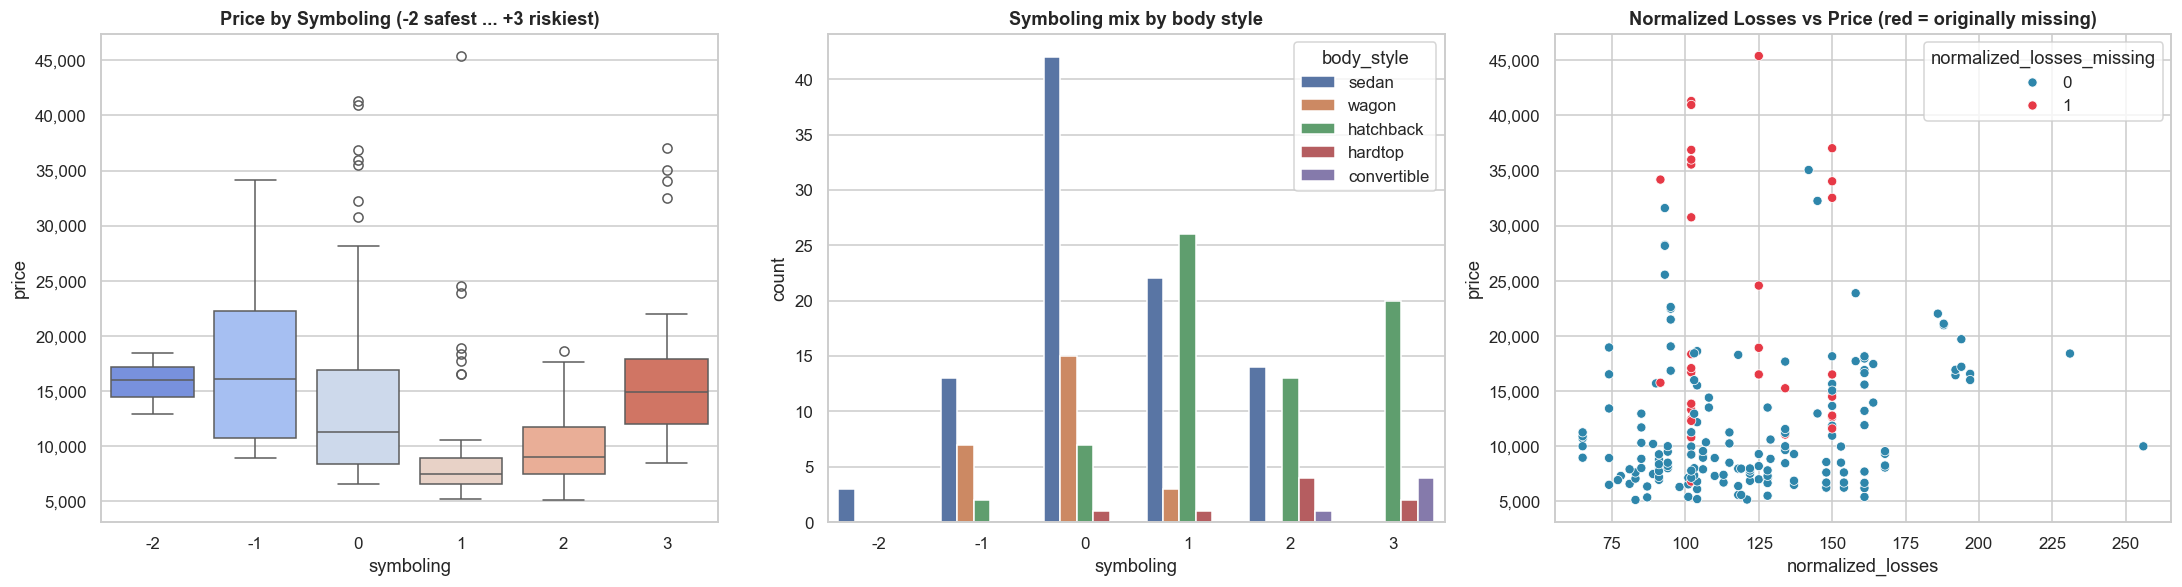

Spearman(symboling, price)          = -0.15
Spearman(normalized_losses, price)  = 0.16


In [42]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
sns.boxplot(data=clean, x='symboling', y='price', ax=axes[0], palette='coolwarm')
axes[0].set_title('Price by Symboling (-2 safest ... +3 riskiest)')
axes[0].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
sns.countplot(data=clean, x='symboling', hue='body_style', ax=axes[1]); axes[1].set_title('Symboling mix by body style')
sns.scatterplot(data=clean, x='normalized_losses', y='price', hue='normalized_losses_missing', ax=axes[2], palette=['#2E86AB', HIGHLIGHT])
axes[2].set_title('Normalized Losses vs Price (red = originally missing)')
axes[2].yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout(); plt.show()

print(f"Spearman(symboling, price)          = {stats.spearmanr(clean.symboling, clean.price)[0]:.2f}")
print(f"Spearman(normalized_losses, price)  = {stats.spearmanr(clean.normalized_losses, clean.price)[0]:.2f}")

**Insights — Insurance risk rating**
- `symboling` (Spearman −0.15) and `normalized_losses` (0.19 on observed rows) are only weakly related to price.
- They are insurer-assigned ratings a seller would not know, so they are weak candidates for a seller-facing price model.


## 14. Multicollinearity

In [43]:
# Highly correlated pairs (|r| >= 0.80): features carrying nearly the same information
cm = clean[num_features].corr().abs()
pairs = (cm.where(np.triu(np.ones(cm.shape, dtype=bool), k=1)).stack().reset_index()
           .rename(columns={'level_0': 'feature_a', 'level_1': 'feature_b', 0: '|r|'}))
pairs[pairs['|r|'] >= 0.80].sort_values('|r|', ascending=False).reset_index(drop=True)

,feature_a,feature_b,|r|
0,city_mpg,highway_mpg,0.97
1,length,curb_weight,0.88
2,wheel_base,length,0.88
3,width,curb_weight,0.87
4,length,width,0.86
5,curb_weight,engine_size,0.85
6,engine_size,horsepower,0.82
7,horsepower,city_mpg,0.82
8,wheel_base,width,0.81
9,horsepower,highway_mpg,0.80


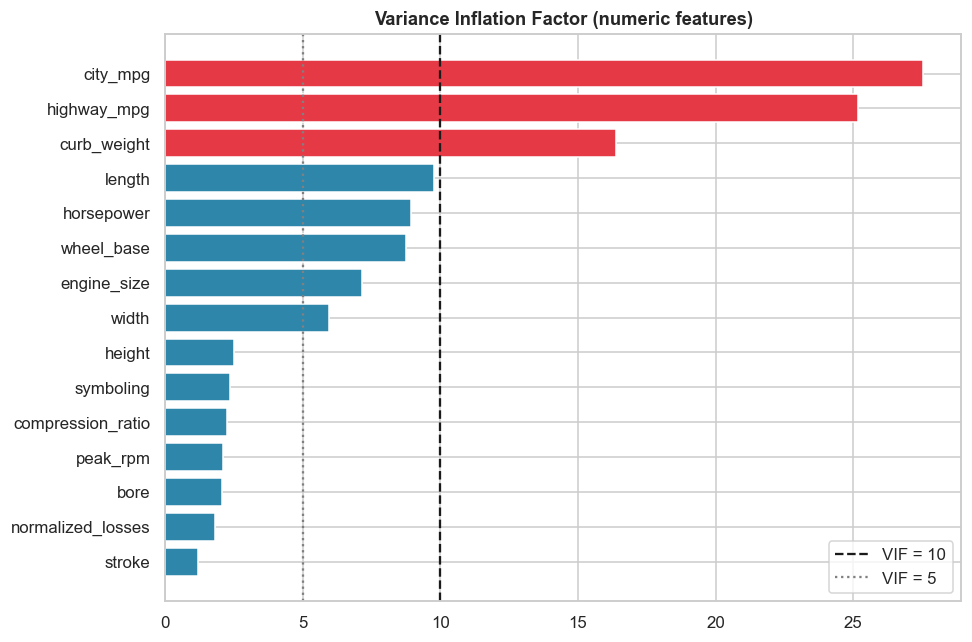

,VIF
city_mpg,27.60
highway_mpg,25.20
curb_weight,16.40
length,9.80
horsepower,8.90
wheel_base,8.70
engine_size,7.10
width,6.00
height,2.50
symboling,2.40


In [44]:
# Variance Inflation Factor (computed with numpy, no extra dependency). VIF > 10 = serious redundancy.
def vif_table(frame):
    Z = (frame - frame.mean()) / frame.std()
    out = {}
    for c in Z.columns:
        y = Z[c].values; Xo = np.c_[np.ones(len(Z)), Z.drop(columns=c).values]
        beta, *_ = np.linalg.lstsq(Xo, y, rcond=None)
        r2 = 1 - ((y - Xo @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out[c] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

vif = vif_table(clean[num_features])
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(vif.index[::-1], vif.values[::-1], color=[HIGHLIGHT if v > 10 else ACCENT for v in vif.values[::-1]])
ax.axvline(10, color='k', ls='--', label='VIF = 10'); ax.axvline(5, color='gray', ls=':', label='VIF = 5')
ax.set_title('Variance Inflation Factor (numeric features)'); ax.legend()
plt.tight_layout(); plt.show()
vif.round(1).to_frame('VIF')

**Insights — Multicollinearity**
- The strongest overlaps are city/highway MPG (0.97), length with curb weight and wheel base (0.88), width with curb weight (0.87) and engine size with curb weight (0.85); engine size and horsepower correlate at 0.82.
- VIF confirms serious redundancy for city MPG (27.6), highway MPG (25.2) and curb weight (16.4).
- Implication: keep one economy measure, and prefer regularised or tree-based models over plain linear regression on all the size variables.


## 15. Feature Engineering Ideas

In [45]:
fe = clean.copy()
fe['power_to_weight']   = fe['horsepower'] / fe['curb_weight'] * 1000
fe['volume_proxy']      = fe['length'] * fe['width'] * fe['height'] / 1e6
fe['avg_mpg']           = (fe['city_mpg'] + fe['highway_mpg']) / 2
fe['hp_per_litre_proxy']= fe['horsepower'] / fe['engine_size']
fe['displacement_calc'] = fe['bore'] * fe['bore'] * fe['stroke']
fe['mpg_gap']           = fe['highway_mpg'] - fe['city_mpg']
# CAUTION: brand tier was derived from median PRICE on the full dataset, so this flag is target-derived.
# It is shown here only to size the brand effect. In a model it must be built inside each CV fold (or replaced by `make`).
fe['is_premium_brand']  = fe['make'].isin(brand.index[brand['tier'] == 'Premium']).astype(int)

new_feats = ['power_to_weight', 'volume_proxy', 'avg_mpg', 'hp_per_litre_proxy', 'displacement_calc', 'mpg_gap', 'is_premium_brand']
comp = pd.DataFrame({
    'Pearson vs price': fe[new_feats].corrwith(fe['price']),
    'Pearson vs log(price)': fe[new_feats].corrwith(np.log(fe['price'])),
    'Spearman vs price': fe[new_feats].corrwith(fe['price'], method='spearman'),
}).sort_values('Pearson vs log(price)', key=abs, ascending=False)
comp

,Pearson vs price,Pearson vs log(price),Spearman vs price
avg_mpg,-0.70,-0.78,-0.83
is_premium_brand,0.76,0.73,0.65
volume_proxy,0.63,0.70,0.72
displacement_calc,0.53,0.60,0.66
power_to_weight,0.51,0.52,0.49
hp_per_litre_proxy,0.13,0.23,0.31
mpg_gap,-0.24,-0.22,-0.19


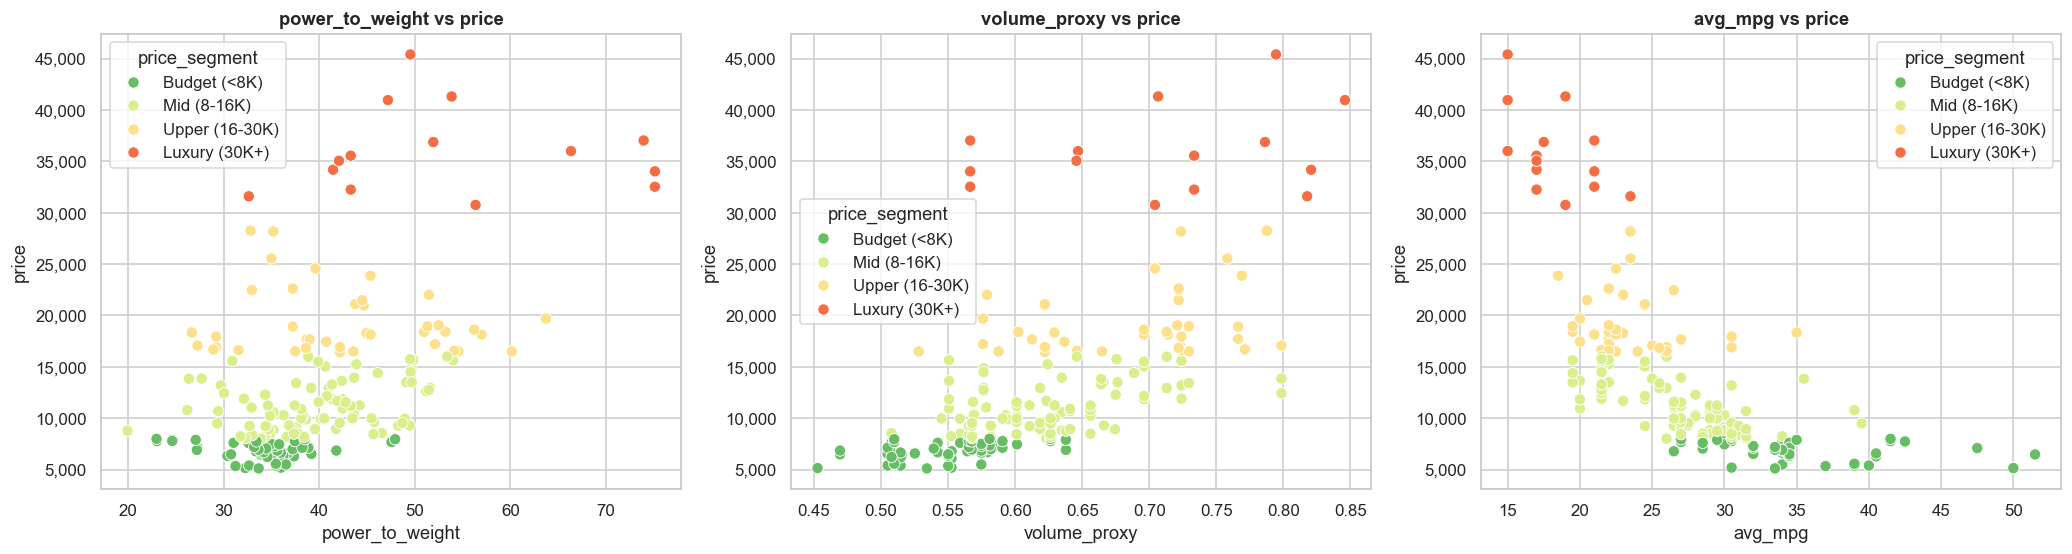

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, col in zip(axes, ['power_to_weight', 'volume_proxy', 'avg_mpg']):
    sns.scatterplot(data=fe, x=col, y='price', hue='price_segment', ax=ax, s=55, palette='RdYlGn_r')
    ax.set_title(f'{col} vs price'); ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout(); plt.show()

In [47]:
# Save the cleaned dataset (with the missing-value flag and segment labels) for the modelling notebook.
clean.drop(columns=['specs_only_resid']).to_csv('automobile_cleaned.csv', index=False)
print('Saved automobile_cleaned.csv ->', clean.drop(columns=['specs_only_resid']).shape)

Saved automobile_cleaned.csv -> (200, 28)


**Insights — Engineered features**
- `avg_mpg` is the strongest engineered feature (r = −0.78 with log price) and removes the MPG redundancy; `volume_proxy` (0.70) and `displacement_calc` (0.60) carry moderate signal; `power_to_weight` (0.52) is weaker.
- `is_premium_brand` correlates at about 0.75, but it is built from price, so it is target-derived and must not be used as a model input.
- Whether these features add value beyond the originals can only be confirmed in modelling.


## 16. EDA Findings & Insights

### Data Quality
- 200 vehicles, no duplicates, no impossible values. One label typo (`peugot`) corrected.
- `normalized_losses` is missing for 18% of cars, and **not at random**: it is missing for every Alfa Romeo, Isuzu, Mercury and Renault, and for most Porsche, Jaguar and BMW cars. Cars with the gap have a median price of 16,500 versus 9,268 for cars without (Mann-Whitney p ≈ 1.5e-08). A missing-value flag was kept so that signal is not lost.

### The Target (historical sold price)
- Sold price is right-skewed (skew 1.81; mean 13,206 vs median 10,270; range 5,118 to 45,400). Taking the log reduces skew to 0.68.
- Historical sales are concentrated in the lower tiers: 30.5% of cars are Budget (<8K), 43% Mid (8-16K), 19.5% Upper (16-30K) and only 7% (14 cars) Luxury (30K+). The luxury tier has a mean engine of about 237 cu in and 184 hp versus about 96 cu in and 70 hp for Budget cars.

### What Drives Sold Price (numeric)
- Strongest: **engine size (r = 0.87), curb weight (0.83; 0.89 vs log price), horsepower (0.81), width (0.75)**, then length (0.69). Fuel economy runs the other way: highway MPG -0.71, city MPG -0.69.
- Height, peak RPM, normalized losses, symboling, stroke and compression ratio show almost no relationship with price on their own.
- Relationships curve upward at the top end (price rises faster than size or power), and are closer to linear against log(price).
- Specs alone (engine size, weight, horsepower) explain about 85% of the variance in log-price in-sample, so most, but not all, of the sold price is explained by physical specifications. Age, mileage and condition (absent from this data) would explain part of the rest.

### What Drives Sold Price (categorical)
- **Make** explains the most (eta² 0.72, but with 22 levels over 200 cars it is partly mechanical), followed by **cylinders (0.53), fuel system (0.52) and drive wheels (0.47)**. Rear-wheel-drive cars have a median price of 16,913 versus 8,192 for front-wheel drive.
- Median price rises with cylinder count: four-cylinder 8,949 vs six 21,038, eight 38,008.
- Body style matters moderately (0.15): hardtop and convertible cost the most (medians about 19,688 and 17,669), hatchbacks the least (8,672).
- Number of doors is not significant (p = 0.06) and fuel type alone is weak (eta² 0.02).
- Aspiration interacts with fuel: turbo adds a large premium (gas 14,489 vs 9,549; diesel 17,075 vs 7,898), though diesel-standard has only 7 cars.

### Brand
- Premium makes (Jaguar, Porsche, Mercedes-Benz, BMW, Volvo, Audi) command the highest medians, from about 17.6K for Audi up to 35.6K for Jaguar; Honda, Chevrolet, Plymouth and Dodge sit lowest (6.3K to 7.6K).
- For a seller, brand matters beyond specs. After controlling for engine size, weight and power (simple in-sample fit), **Porsche (about +52%), BMW (+44%) and Audi (+29%)** are priced well above what their specs alone predict, i.e. a genuine brand premium. Jaguar (about -25%), Mercury, Isuzu and Mitsubishi sit below. Jaguar's gap partly reflects very large engines (3 cars) stretching a linear spec model, so treat it cautiously.
- Several makes have only 1-3 cars (Mercury, Jaguar, Chevrolet, Alfa Romeo, Isuzu, Renault), so brand-level estimates for them are fragile.

### Multicollinearity
- The size and economy variables are highly redundant: city and highway MPG (r = 0.97), length with curb weight and wheel base (r = 0.88), width with curb weight (0.87).
- VIF is above 10 for city MPG (27.6), highway MPG (25.2) and curb weight (16.4); length (9.8), horsepower (8.9) and wheel base (8.7) are close behind.

### Outliers
- The extreme values are real premium cars (Mercedes-Benz, BMW, Porsche, Jaguar) and should be kept, not removed.
- The high outlier share on `compression_ratio` (13.5%) comes from diesel engines, which legitimately run much higher compression.

### What a Seller Could Realistically Enter
- Easy for a seller to supply: make, body style, number of doors, drive wheels, fuel type, aspiration, engine size, cylinders, horsepower, curb weight, dimensions, and city/highway MPG (all are on the car's spec sheet or registration).
- **Not realistic for a seller:** `symboling` and `normalized_losses` are insurance risk ratings assigned by insurers, and the missing-value flag for `normalized_losses` is a data artefact, not something a seller knows. They show weak price signal anyway (|r| ≤ 0.2), so they are good candidates to **drop from the seller-facing model**.
- Internal engine details (`bore`, `stroke`, `compression_ratio`, `peak_rpm`, `fuel_system`) are rarely known by sellers and are partly redundant with engine size and horsepower.

### Engineered Feature Candidates
- `avg_mpg` (r = -0.78 vs log price), `volume_proxy` (0.70) and `displacement_calc` (0.60) carry useful signal; `power_to_weight` (0.52) is moderate; `hp_per_litre_proxy` and `mpg_gap` are weak.
- `is_premium_brand` correlates at 0.73-0.76, but it is built from price and is therefore target-derived. It must not be used as-is in a model.
